In [1]:
# === Imports ===
import numpy as np  # Array operations
import matplotlib.pyplot as plt  # Plotting
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap, to_rgba_array # For the color scheme
import pandas as pd  # Data handling
import pyp2options  # Custom library --> Calibrations
from astropy.coordinates import SkyCoord  # Astronomical coordinate handling
import astropy.units as u  # Physical units
import scipy.optimize as spopt  # Optimization algorithms
import scipy.stats as st
from scipy.stats import gaussian_kde
import sys
#from matplotlib.backends.backend_pdf import PdfPages  # Save multiple figures into a PDF

In [2]:
# === Color Scheme ===
def discretemap(colormap, hexclrs):
    """
    Produce a colormap from a list of discrete colors without interpolation.
    """
    clrs = to_rgba_array(hexclrs)
    clrs = np.vstack([clrs[0], clrs, clrs[-1]])
    cdict = {}
    for ki, key in enumerate(('red','green','blue')):
        cdict[key] = [ (i/(len(clrs)-2.), clrs[i, ki], clrs[i+1, ki]) for i in range(len(clrs)-1) ]
    return LinearSegmentedColormap(colormap, cdict)

class TOLcmaps:
    """
    Simplified TOLcmaps with only 'nightfall_discrete' and 'YlOrBr_discrete'.
    """
    def __init__(self):
        self.cmap = None
        self.cname = None
        self.namelist = ('nightfall_discrete', 'YlOrBr_discrete')
        self.funcdict = {
            'nightfall_discrete': self.__nightfall_discrete,
            'YlOrBr_discrete': self.__YlOrBr_discrete,
        }

    def __nightfall_discrete(self):
        clrs = ['#125A56', '#238F9D', '#60BCE9', '#C6DBED', '#ECEADA',
                '#F9D576', '#FD9A44', '#E94C1F', '#A01813']
        self.cmap = discretemap(self.cname, clrs)
        self.cmap.set_bad('#FFFFFF')

    def __YlOrBr_discrete(self):
        clrs = ['#FFFFE5', '#FFF7BC', '#FEE391', '#FEC44F', '#FB9A29',
                '#EC7014', '#CC4C02', '#993404', '#662506']
        self.cmap = discretemap(self.cname, clrs)
        self.cmap.set_bad('#888888')

    def show(self):
        print(' '.join(self.namelist))

    def get(self, cname='nightfall_discrete'):
        self.cname = cname
        if cname in self.funcdict:
            self.funcdict[cname]()
            return self.cmap
        else:
            raise ValueError(f"Colormap {cname} is not available. Choose from {self.namelist}.")

def tol_cmap(colormap=None):
    """
    Return matplotlib colormap. Only 'nightfall_discrete' and 'YlOrBr_discrete' supported.
    """
    obj = TOLcmaps()
    if colormap is None:
        return obj.namelist
    return obj.get(colormap)

In [3]:
# === Defined Parameters ===
field_name = 'MISHAPS_F1_DITH0'  # Field identifier
chip_id = 'N10'  # Chip identifier
magnitude_band = 'g'  # Band used for magnitude measurement
color_band_1 = 'g'  # First band for color (e.g. r-z)
color_band_2 = 'i'  # Second band for color
field_chip_label = f"{field_name}_{chip_id}"  # Combined label for file references

# CMD (Color-Magnitude Diagram) Parameters
default_color_cut = 1.06
magnitude_cut_g = 19
magnitude_cut_i = 17.5
color_range_min = 0.0
color_range_max = 2.0
msto_shift_value = 3.5  # Main Sequence Turn-Off shift

# Adjust defaults for specific color combinations
if color_band_2 == "i" and color_band_1 == "g":
    # default_color_cut = 0.46
    default_color_cut_gi = 1.2
    color_range_max = 1.0
    msto_shift_value = 3.0

In [4]:
# Enable interactive plots if enough command-line arguments are provided
interactive_mode = False
if len(sys.argv) >= 6:
    interactive_mode = True

# Optionally override color and magnitude cuts
if len(sys.argv) >= 7:
    default_color_cut = float(sys.argv[6])
    print("Color cut set to:", default_color_cut)

if len(sys.argv) >= 8:
    magnitude_cut = float(sys.argv[7])
    print("Magnitude cut set to:", magnitude_cut)

print("Using magnitude and color bands:", magnitude_band, color_band_1, color_band_2)

Using magnitude and color bands: g g i


In [5]:
# Optional positional filtering via RA/Dec limits
ra_min, ra_max = -1, -1
dec_min, dec_max = -1, -1
apply_position_cut = False

if len(sys.argv) >= 9:
    ra_min = float(sys.argv[8])
    ra_max = float(sys.argv[9])
    dec_min = float(sys.argv[10])
    dec_max = float(sys.argv[11])
    apply_position_cut = True

In [6]:
# === Load in MISHAPS File ===
#catalog_path = "/home/bernthold.17/SURP2025/Data_Files/" + field_chip_label + ".cmd.calibrate_ps"
catalog_path = "/Users/erin/Documents/GitHub/SURP2025/Data_Files/" + field_chip_label + ".cmd.calibrate_ps"
contents = pd.read_csv(catalog_path, header = None, sep = '\\s+')

In [7]:
# === Apply Column Headers ===
column_labels = ['ID', 'RA_z', 'Dec_z', 'ID_z', 'X_z', 'Y_z', 'mis_z', 'mis_z_err', 'Sky_z', 'qflag_z', '?1z', '?2z',
       'RA_r', 'Dec_r', 'ID_r', 'X_r', 'Y_r', 'mis_r', 'mis_r_err', 'Sky_r', 'qflag_r', '?1r', '?2r',
       'RA_u', 'Dec_u', 'ID_u', 'X_u', 'Y_u', 'mis_u', 'mis_u_err', 'Sky_u', 'qflag_u', '?1u', '?2u',
       'RA_g', 'Dec_g', 'ID_g', 'X_g', 'Y_g', 'mis_g', 'mis_g_err', 'Sky_g', 'qflag_g', '?1g', '?2g',
       'RA_i', 'Dec_i', 'ID_i', 'X_i', 'Y_i', 'mis_i', 'mis_i_err', 'Sky_i', 'qflag_i', '?1i', '?2i',
       'RA_Y', 'Dec_Y', 'ID_Y', 'X_Y', 'Y_Y', 'mis_Y', 'mis_Y_err', 'Sky_Y', 'qflag_Y', '?1Y', '?2Y']
              
contents.columns = column_labels

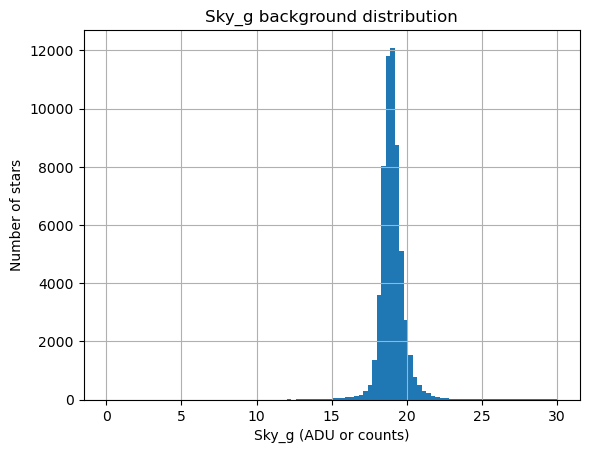

0.90    19.887630
0.95    20.326565
0.98    21.202688
0.99    22.684416
Name: Sky_g, dtype: float64


In [8]:
# === Determine the Best Cut-Off Value for Sky Background Threshold ===
# For the g-band
# Show the distribution and upper percentiles
contents['Sky_g'].hist(bins=100, range=(0, 30))

plt.title("Sky_g background distribution")
plt.xlabel("Sky_g (ADU or counts)")
plt.ylabel("Number of stars")

plt.grid(True)
plt.show()

# Quantiles
print(contents['Sky_g'].quantile([0.90, 0.95, 0.98, 0.99]))

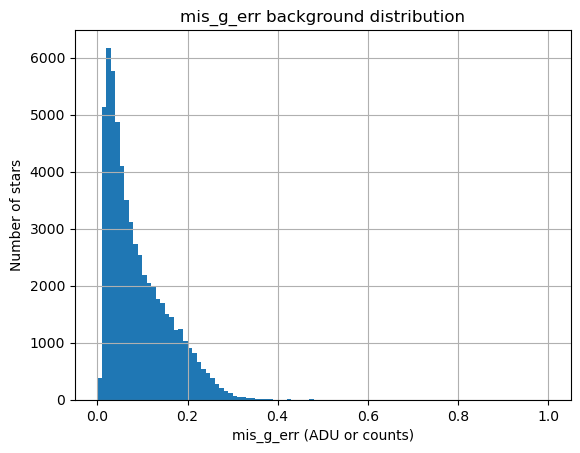

0.90    0.188813
0.95    0.220930
0.98    0.254233
0.99    0.274890
Name: mis_g_err, dtype: float64


In [9]:
# Show the distribution and upper percentiles
# For the i-band
contents['mis_g_err'].hist(bins=100, range=(0, 1))

plt.title("mis_g_err background distribution")
plt.xlabel("mis_g_err (ADU or counts)")
plt.ylabel("Number of stars")

plt.grid(True)
plt.show()

# Quantiles
print(contents['mis_g_err'].quantile([0.90, 0.95, 0.98, 0.99]))

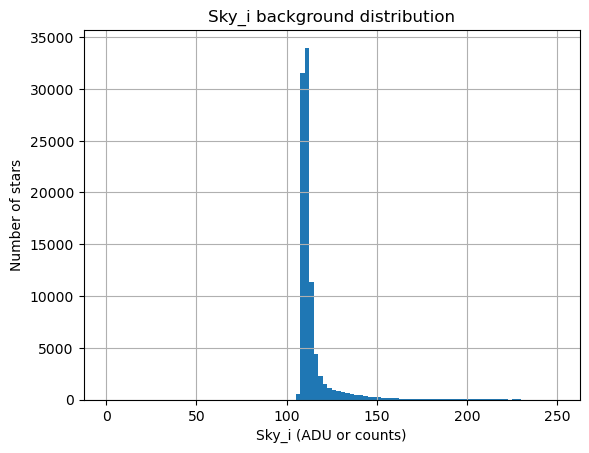

0.90    120.515360
0.95    132.492830
0.98    148.535512
0.99    162.826318
Name: Sky_i, dtype: float64


In [10]:
# Show the distribution and upper percentiles
# For the i-band
contents['Sky_i'].hist(bins=100, range=(0, 250))

plt.title("Sky_i background distribution")
plt.xlabel("Sky_i (ADU or counts)")
plt.ylabel("Number of stars")

plt.grid(True)
plt.show()

# Quantiles
print(contents['Sky_i'].quantile([0.90, 0.95, 0.98, 0.99]))

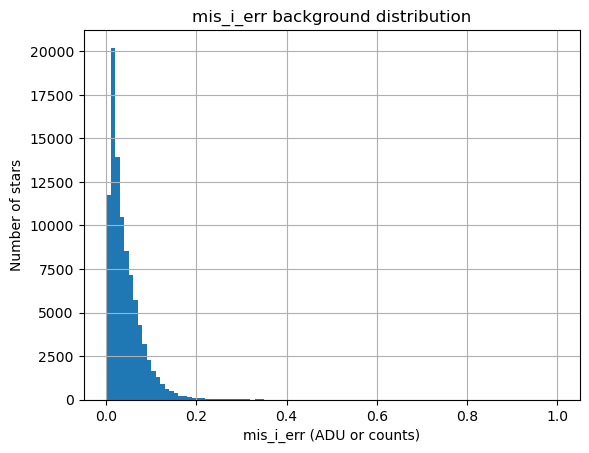

0.90    0.087230
0.95    0.110160
0.98    0.140396
0.99    0.165738
Name: mis_i_err, dtype: float64


In [11]:
# Show the distribution and upper percentiles
# For the i-band
contents['mis_i_err'].hist(bins=100, range=(0, 1))

plt.title("mis_i_err background distribution")
plt.xlabel("mis_i_err (ADU or counts)")
plt.ylabel("Number of stars")

plt.grid(True)
plt.show()

# Quantiles
print(contents['mis_i_err'].quantile([0.90, 0.95, 0.98, 0.99]))

In [12]:
# === Apply Quality Filters ===
print(contents.shape)

mask_flags = (contents['qflag_i'] == 1) & (contents['qflag_g'] == 1)
mask_err = (contents['mis_g_err'] < 0.2) & (contents['mis_i_err'] < 0.2)
mask_sky = (contents["Sky_g"] < 25) & (contents["Sky_i"] < 170)

# print(contents[['qflag_g', 'qflag_i', 'mis_g_err', 'mis_i_err', 'Sky_g', 'Sky_i']].describe(include='all'))

combined_mask = mask_flags & mask_err & mask_sky
filtered_contents = contents[combined_mask]

print(filtered_contents.shape)

(101166, 67)
(14647, 67)


In [13]:
# === Define Magnitudes and Color ===
g = filtered_contents.loc[:, 'mis_g']
i = filtered_contents.loc[:, 'mis_i']
gmi = filtered_contents.loc[:, 'mis_g'] - filtered_contents.loc[:, 'mis_i']

# === Define Position ===
ra_g = filtered_contents.loc[:, 'RA_g']
dec_g = filtered_contents.loc[:, 'Dec_g']

ra_i = filtered_contents.loc[:, 'RA_i']
dec_i = filtered_contents.loc[:, 'Dec_i']

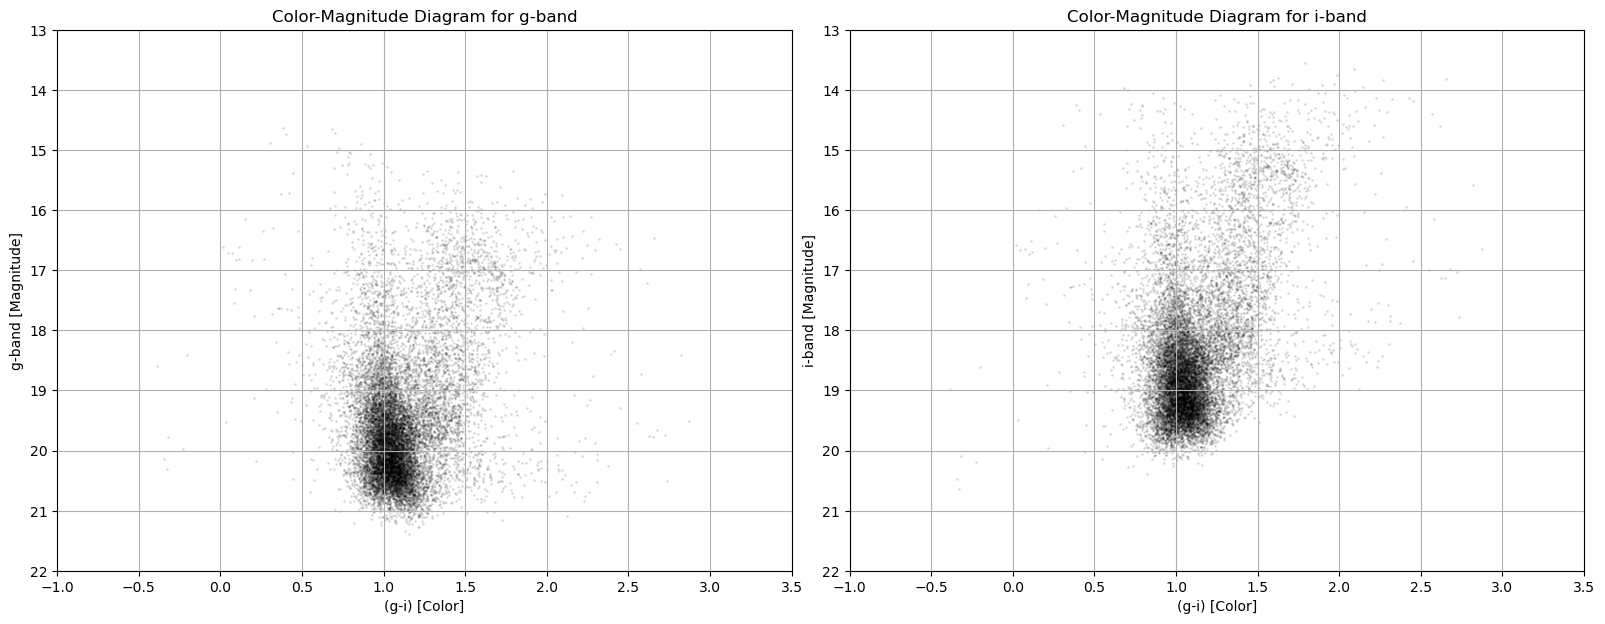

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot CMD for g-mag on the first subplot (ax1) ---
ax1.scatter(gmi, g, s=1, color='black', alpha=0.1)

ax1.set_xlim(-1, 3.5)
ax1.invert_yaxis() # Brighter stars at the top
ax1.set_ylim(22, 13)

ax1.set_xlabel(f"(g-i) [Color]")
ax1.set_ylabel(f"g-band [Magnitude]")
ax1.set_title("Color-Magnitude Diagram for g-band")
ax1.grid(True)

# --- Plot CMD for i-mag on the second subplot (ax2) ---
ax2.scatter(gmi, i, s=1, color='black', alpha=0.1)

ax2.set_xlim(-1, 3.5)
ax2.invert_yaxis() # Brighter stars at the top
ax2.set_ylim(22, 13)

ax2.set_xlabel(f"(g-i) [Color]")
ax2.set_ylabel(f"i-band [Magnitude]") 
ax2.set_title("Color-Magnitude Diagram for i-band")
ax2.grid(True)

plt.show()

In [15]:
# === Red Clump Color Reference Function ===
# The numbers come from the Nataf papers --> Look them up
# l - galactic longitude, b - galactic latitude, our view of a star relative to the galactic center (0, 0)
def red_clump_color(l, b):
    """Returns the expected intrinsic color of the red clump stars given Galactic coordinates."""
    I_0 = 14.3955 - 0.0239 * l + 0.0122 * np.abs(b) # Dereddened I mag of the red clump (rc)
    I_mag = np.array([I_0, I_0 + 0.737, I_0 - 1.07]) # The I mag of the rc, red giant branch (rgbb),
                                                        # and asymptotic giant branch (agbb)
    dis_mod = I_mag - 14.3955 + 5.0 * np.log10(8178.0) - 5.0 # Distance modulus of bar peak density
    distance = 10**(0.2 * (dis_mod + 5.0)) # Distance from ... --> Figure it out
    V_mag = 1.060 + I_mag
    
    # Use the relations between U, B, V, R, I mags and Sloan Digital Sky Survey (SDSS) u, g, r, i, z mags to get 
     # the g, r, i, z mags
    g_sdss = V_mag + 0.553 # g sdss filter (mag)
    r_sdss = V_mag - 0.327 # r sdss  filter (mag)
    i_sdss = V_mag - 0.600 # i sdss filter (mag)
    
    gmi_sdss = g_sdss - i_sdss # (g-i) sdss color
    
    rgbb_r_sdss = 1.060 + I_mag + 0.737 - 0.327 # r sdss filter of the red giant branch
    agbb_r_sdss = 1.060 + I_mag - 1.070 - 0.327 # r sdss filter of the asymptotic giant branch
    rgbb_gmi_sdss = 0.553 + 0.600 - 0.060 # (g-i) sdss color of the red giant branch
    agbb_gmi_sdss = 0.553 + 0.600 + 0.200 # (g-i) sdss color of the asymptotic giant branch
    
    print("r sdss:", r_sdss, rgbb_r_sdss, agbb_r_sdss)
    print("gmi sdss:", gmi_sdss, rgbb_gmi_sdss, agbb_gmi_sdss)
    
    # Transforms from SDSS to PanSTARRS
    for i in np.arange(0, 10):
        gpmgs = -0.01808 - 0.13595 * gmi_sdss + 0.01941 * gmi_sdss**2 - 0.00183 * gmi_sdss**3
        rpmrs = -0.01836 - 0.03577 * gmi_sdss + 0.02612 * gmi_sdss**2 - 0.00558 * gmi_sdss**3
        ipmis = 0.01170 - 0.00400 * gmi_sdss + 0.00066 * gmi_sdss**2 - 0.00058 * gmi_sdss**3
        g_ps1 = g_sdss + gpmgs #g panstarrs
        r_ps1 = r_sdss + rpmrs #r panstarrs
        i_ps1 = i_sdss + ipmis #i panstarrs
        gmi_ps1 = g_ps1 - i_ps1 #gmi panstarrs
        rmi_ps1 = r_ps1 - i_ps1 #rmi panstarrs
        imz_ps1 = 0.234625 + 0.211715 * (gmi_ps1 - 1.25) #i-z panstarrs
        rmz_ps1 = rmi_ps1 + imz_ps1 #r-z panstarrs
        z_ps1 = r_ps1 - rmz_ps1 #z panstarrs
        
        print()

    # Return the PanSTARRS magnitudes, distance, and distance modulus as a dictionary
    ret = {"clump-g":g_ps1[0], "clump-r":r_ps1[0], "clump-i":i_ps1[0], "clump-z":z_ps1[0],
           "rgbb-g":g_ps1[1], "rgbb-r":r_ps1[1], "rgbb-i":i_ps1[1], "rgbb-z":z_ps1[1],
           "agbb-g":g_ps1[2], "agbb-r":r_ps1[2], "agbb-i":i_ps1[2], "agbb-z":z_ps1[2],
           "distance":distance[0], "distance_modulus":dis_mod[0]}

    #return zp[0],rmz[0],rp[1]-rp[0],rp[2]-rp[0],gmi[0],dmod[0],d[0]
    #return ip[0],gmi[0],ip[1]-ip[0],ip[2]-ip[0],gmi[0],dmod[0],d[0]

    return ret

In [16]:
ra = np.nanmean(ra_g)
dec = np.nanmean(dec_g) 

# Get the l and b coordinates
coords = SkyCoord(ra, dec, frame = 'icrs', unit = u.deg)
l = coords.galactic.l.value
b = coords.galactic.b.value
print("Galactic Coordinates:", l, b)
global rgbbmag0
global agbbmag0

# Estimate initial red clump guess
red_clump = red_clump_color(l, b)

clumpmag0_g = red_clump["clump-" + magnitude_band]
clumpmag0_i = red_clump["clump-" + color_band_2]
rgbbmag0_g = red_clump["rgbb-" + magnitude_band]
rgbbmag0_i = red_clump["rgbb-" + color_band_2]
agbbmag0_g = red_clump["agbb-" + magnitude_band]
agbbmag0_i = red_clump["agbb-" + color_band_2]

#clump_M_i = -0.22 # Absolute mag of the rc in the i-band
#mu_i = 5 * np.log10(8000 / 10) 
#clumpmag0_i = clump_M_i + mu_i
#rgbb_M_r = rgbbmag0 - mu_i

print(clumpmag0_g)
print(clumpmag0_i)
print(rgbbmag0_g)
print(rgbbmag0_i)
print(agbbmag0_g)
print(agbbmag0_i)

Galactic Coordinates: 4.833806565418768 -7.899441665978778
r sdss: [15.10934521 15.84634521 14.03934521] [15.84634521 16.58334521 14.77634521] [14.03934521 14.77634521 12.96934521]
gmi sdss: [1.153 1.153 1.153] 1.093 1.353










15.837513650405525
14.843421592376774
16.574513650405525
15.580421592376775
14.767513650405524
13.773421592376774


In [17]:
# === Red Clump Model (Quadratic + Gaussian) for the g-band ===
def rcmodel_g(x, amplitude, slope, magnitude_rc, number_rc, sigma_rc):
    x = np.float64(x)
    A = amplitude*np.exp(slope*(x - magnitude_rc))
    B = number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-magnitude_rc)**2/sigma_rc**2)
    C = 0.201*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+rgbbmag0_g))**2/sigma_rc**2)
    D = 0.028*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+agbbmag0_g))**2/sigma_rc**2)
    return A + B + C + D     

In [18]:
# === Red Clump Model (Quadratic + Gaussian) for the i-band ===
def rcmodel_i(x, amplitude, slope, magnitude_rc, number_rc, sigma_rc):
    x = np.float64(x)
    A = amplitude*np.exp(slope*(x - magnitude_rc))
    B = number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-magnitude_rc)**2/sigma_rc**2)
    C = 0.201*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+rgbbmag0_i))**2/sigma_rc**2)
    D = 0.028*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+agbbmag0_i))**2/sigma_rc**2)
    return A + B + C + D  

In [19]:
# === Red Clump Gaussian ===
def cgauss(x, amplitude, mean, sigma):
    x = np.float64(x)
    return amplitude/(np.sqrt(2*np.pi*sigma**2))*np.exp(-0.5*(x-mean)**2/sigma**2)

In [20]:
# === Giant Star Selection (g-band) ===
# Filter stars that are likely giants
# Filter for the giants
giant_candidates_g = filtered_contents[(gmi > default_color_cut) & (g < magnitude_cut_g)]

giant_colors_g = giant_candidates_g['mis_g'] - giant_candidates_g['mis_i']
giant_magnitudes_g = giant_candidates_g['mis_g']

print(f"Selected {len(giant_candidates_g)} giant star candidates in the g-band")

# For the magnitude distribution fit of the whole red giant branch
# Create a histogram of magnitudes
hist_counts_giant_g, bin_edges_giant_g = np.histogram(giant_magnitudes_g, range = (magnitude_cut_g - 4.0, magnitude_cut_g), bins = 60, density = False) # bins the magnitudes of the giants
bin_centers_giant_g = 0.5 * (bin_edges_giant_g[0:-1] + bin_edges_giant_g[1:]) # calculates bin centers from the bin edges

#bin_edges_giant = np.linspace(min(giant_magnitudes), max(giant_magnitudes), 50)
#bin_centers_giant = 0.5 * (bin_edges_giant[1:] + bin_edges_giant[:-1])
#hist_counts_giant, _ = np.histogram(giant_magnitudes, bins = bin_edges_giant)

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_0g = (hist_counts_giant_g>0)
hist_counts_m0g = hist_counts_giant_g[mask_0g]
bin_centers_m0g = bin_centers_giant_g[mask_0g]

#print(type(bin_centers_m0))
#print(bin_centers_m0)

initial_guess_2 = [25.0, 0.5, 17.0, 35.0, 0.4] # Initial guess for the curve fit

par_0g, cov_0g = spopt.curve_fit(rcmodel_g, bin_centers_m0g, hist_counts_m0g, p0 = initial_guess_2, sigma = np.sqrt(hist_counts_m0g))
print(f"rcmodel Fit Results for the g-Band:\nAmplitude = {par_0g[0]:.2f}\n  Slope = {par_0g[1]:.2f}\n Magnitude of red clump = {par_0g[2]:.2f}\n  Number of red clump stars = {par_0g[3]:.2f}\n  Sigma = {par_0g[4]:.2f}")

amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_0g

# === Giant Star Selection (i-band) ===
giant_candidates_i = filtered_contents[(gmi > default_color_cut) & (i < magnitude_cut_i)]

giant_colors_i = giant_candidates_i['mis_g'] - giant_candidates_i['mis_i']
giant_magnitudes_i = giant_candidates_i['mis_i']

print(f"Selected {len(giant_candidates_i)} giant star candidates in the i-band")

hist_counts_giant_i, bin_edges_giant_i = np.histogram(giant_magnitudes_i, range=(magnitude_cut_i - 4.0, magnitude_cut_i), bins = 60, density = False) # bins the magnitudes of the giants
bin_centers_giant_i = 0.5 * (bin_edges_giant_i[0:-1] + bin_edges_giant_i[1:]) # calculates bin centers from the bin edges

mask_0i = (hist_counts_giant_i>0)
hist_counts_m0i = hist_counts_giant_i[mask_0i]
bin_centers_m0i = bin_centers_giant_i[mask_0i]

initial_guess_0 = [40.0, 0.5, 15.0, 30.0, 0.3] # Initial guess for the curve fit
initial_guess_2i = [30.0, 0.5, 15.8, 60.0, 0.3]
initial_guess_4 = [20.0, 0.5, 15.35, 25.0, 0.25]

par_0i, cov_0i = spopt.curve_fit(rcmodel_i, bin_centers_m0i, hist_counts_m0i, p0 = initial_guess_4, sigma = np.sqrt(hist_counts_m0i))
print(f"rcmodel Fit Results for the i-Band:\nAmplitude = {par_0i[0]:.2f}\n  Slope = {par_0i[1]:.2f}\n Magnitude of red clump = {par_0i[2]:.2f}\n  Number of red clump stars = {par_0i[3]:.2f}\n  Sigma = {par_0i[4]:.2f}")

amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_0i

Selected 2133 giant star candidates in the g-band
rcmodel Fit Results for the g-Band:
Amplitude = 13.68
  Slope = 0.98
 Magnitude of red clump = 16.94
  Number of red clump stars = 37.65
  Sigma = 0.46
Selected 1892 giant star candidates in the i-band
rcmodel Fit Results for the i-Band:
Amplitude = 10.79
  Slope = 0.97
 Magnitude of red clump = 15.42
  Number of red clump stars = 40.40
  Sigma = 0.54


In [21]:
print(f"default_color_cut: {default_color_cut}, magnitude_cut_g: {magnitude_cut_g}")
print(f"gmi range: {gmi.min()} to {gmi.max()}")
print(f"g range: {g.min()} to {g.max()}")

default_color_cut: 1.06, magnitude_cut_g: 19
gmi range: -0.3858099999999993 to 6.312849999999999
g range: 14.62804 to 21.39652


In [22]:
print(f"Red Clump magnitude (g): {par_0g[2]}")
print(f"Red Clump sigma (g): {par_0g[4]}")
print(f"g-range of giants: {giant_magnitudes_g.min()} to {giant_magnitudes_g.max()}")

Red Clump magnitude (g): 16.93923510944805
Red Clump sigma (g): 0.4620499625879435
g-range of giants: 15.34742 to 18.99877


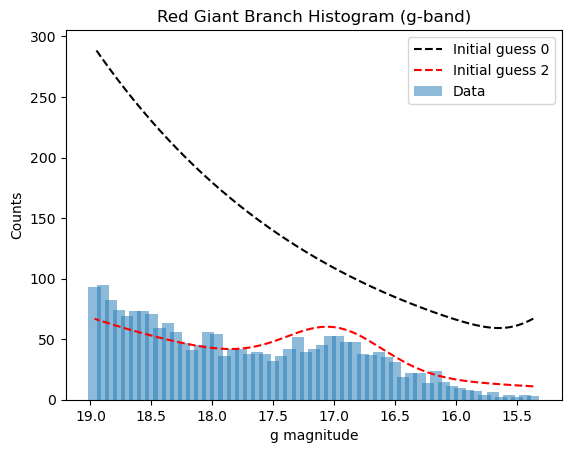

In [23]:
initial_guess_2 = [25.0, 0.5, 17.0, 35.0, 0.4]
plt.bar(bin_centers_m0g, hist_counts_m0g, width=0.1, alpha=0.5, label="Data")
x_fit = np.linspace(min(bin_centers_m0g), max(bin_centers_m0g), 500)
y_fit_0 = rcmodel_g(x_fit, *initial_guess_0)
y_fit_2 = rcmodel_g(x_fit, *initial_guess_2)
plt.plot(x_fit, y_fit_0, 'k--', label="Initial guess 0")
plt.plot(x_fit, y_fit_2, 'r--', label="Initial guess 2")
plt.xlabel("g magnitude")
plt.ylabel("Counts")
plt.title("Red Giant Branch Histogram (g-band)")
plt.legend()
plt.gca().invert_xaxis()
plt.show()

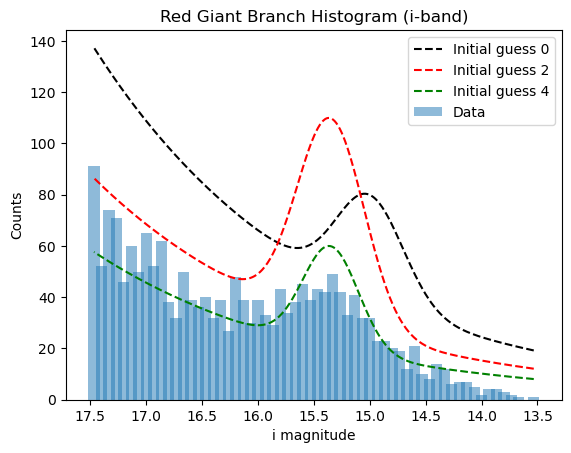

In [24]:
initial_guess_2 = [30.0, 0.5, 15.35, 60.0, 0.3]
initial_guess_4 = [20.0, 0.5, 15.35, 25.0, 0.25]
plt.bar(bin_centers_m0i, hist_counts_m0i, width=0.1, alpha=0.5, label="Data")
x_fit = np.linspace(min(bin_centers_m0i), max(bin_centers_m0i), 500)
y_fit_0 = rcmodel_i(x_fit, *initial_guess_0)
y_fit_2 = rcmodel_i(x_fit, *initial_guess_2)
y_fit_4 = rcmodel_i(x_fit, *initial_guess_4)
plt.plot(x_fit, y_fit_0, 'k--', label="Initial guess 0")
plt.plot(x_fit, y_fit_2, 'r--', label="Initial guess 2")
plt.plot(x_fit, y_fit_4, 'g--', label="Initial guess 4")
plt.xlabel("i magnitude")
plt.ylabel("Counts")
plt.title("Red Giant Branch Histogram (i-band)")
plt.legend()
plt.gca().invert_xaxis()
plt.show()

In [25]:
# === Red Clump Star Selection (g-band) ===
# Filter stars that are likely within the red clump
clump_candidates_g = giant_candidates_g[np.abs(giant_candidates_g['mis_g'] - par_0g[2]) < 2 * par_0g[4]]

clump_colors_g = clump_candidates_g['mis_g'] - clump_candidates_g['mis_i']
clump_magnitudes_g = clump_candidates_g['mis_g']

print(f"Selected {len(clump_candidates_g)} red clump candidates in the g-band")

# For the color distribution fit of stars in the red clump
# Create a histogram of colors
hist_counts_clump_g, bin_edges_clump_g = np.histogram(clump_colors_g, range = (default_color_cut, default_color_cut + 1.5), bins=60)
bin_centers_clump_g = 0.5 * (bin_edges_clump_g[:-1] + bin_edges_clump_g[1:])

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_1g = (hist_counts_clump_g>0)
hist_counts_m1g = hist_counts_clump_g[mask_1g]
bin_centers_m1g = bin_centers_clump_g[mask_1g]

# Initial guess for Gaussian parameters: amplitude, mean, sigma
initial_guess_1 = [par_0g[3] + 0.0, default_color_cut + 0.2, 0.2]

par_1g, cov_1g = spopt.curve_fit(cgauss, bin_centers_m1g, hist_counts_m1g, p0 = initial_guess_1, sigma=np.sqrt(hist_counts_m1g))
print(f"cgauss Model Fit Results:\nAmplitude = {par_1g[0]:.2f}\n  Mean = {par_1g[1]:.2f}\n Sigma = {par_1g[2]:.2f}")

amplitude, mean, sigma = par_1g

# === Red Clump Star Selection (i-band) ===
#clump_candidates_i = giant_candidates_i[np.abs(giant_candidates_i['mis_i'] - par_0i[2]) < 2 * par_0i[4]]
clump_candidates_i = giant_candidates_i[np.abs(giant_candidates_i['mis_i'] - par_0i[2]) < 1.5 * par_0i[4]]
clump_colors_i = clump_candidates_i['mis_g'] - clump_candidates_i['mis_i']
clump_magnitudes_i = clump_candidates_i['mis_i']

print(f"Selected {len(clump_candidates_i)} red clump candidates in the i-band")

hist_counts_clump_i, bin_edges_clump_i = np.histogram(clump_colors_i, range = (default_color_cut, default_color_cut + 1.5), bins=60)
bin_centers_clump_i = 0.5 * (bin_edges_clump_i[:-1] + bin_edges_clump_i[1:])

mask_1i = (hist_counts_clump_i>0)
hist_counts_m1i = hist_counts_clump_i[mask_1i]
bin_centers_m1i = bin_centers_clump_i[mask_1i]

initial_guess_1i = [par_0i[3] + 0.0, default_color_cut + 0.2, 0.2]
initial_guess_3 = [25.0, default_color_cut + 0.2, 0.2]

par_1i, cov_1i = spopt.curve_fit(cgauss, bin_centers_m1i, hist_counts_m1i, p0 = initial_guess_3, sigma=np.sqrt(hist_counts_m1i))
print(f"cgauss Model Fit Results:\nAmplitude = {par_1i[0]:.2f}\n  Mean = {par_1i[1]:.2f}\n Sigma = {par_1i[2]:.2f}")

amplitude, mean, sigma = par_1i

Selected 993 red clump candidates in the g-band
cgauss Model Fit Results:
Amplitude = 24.33
  Mean = 1.45
 Sigma = 0.23
Selected 827 red clump candidates in the i-band
cgauss Model Fit Results:
Amplitude = 19.73
  Mean = 1.48
 Sigma = 0.21


37.649325334407195 1.26


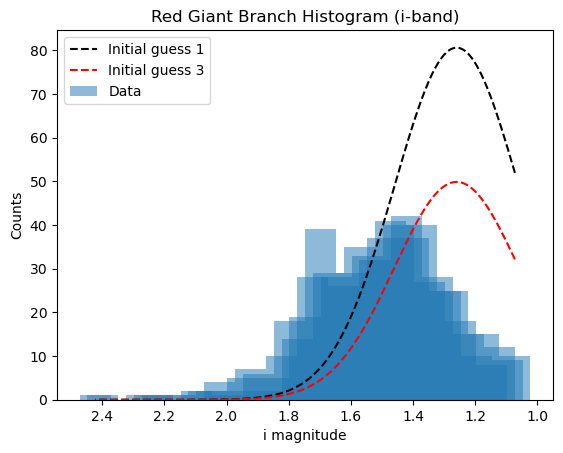

In [26]:
print(par_0g[3], default_color_cut + 0.2)
initial_guess_3 = [25.0, default_color_cut + 0.2, 0.2]
plt.bar(bin_centers_m1i, hist_counts_m1i, width=0.1, alpha=0.5, label="Data")
x_fit = np.linspace(min(bin_centers_m1i), max(bin_centers_m1i), 500)
y_fit_1 = cgauss(x_fit, *initial_guess_1i)
y_fit_3 = cgauss(x_fit, *initial_guess_3)
plt.plot(x_fit, y_fit_1, 'k--', label="Initial guess 1")
plt.plot(x_fit, y_fit_3, 'r--', label="Initial guess 3")
plt.xlabel("i magnitude")
plt.ylabel("Counts")
plt.title("Red Giant Branch Histogram (i-band)")
plt.legend()
plt.gca().invert_xaxis()
plt.show()

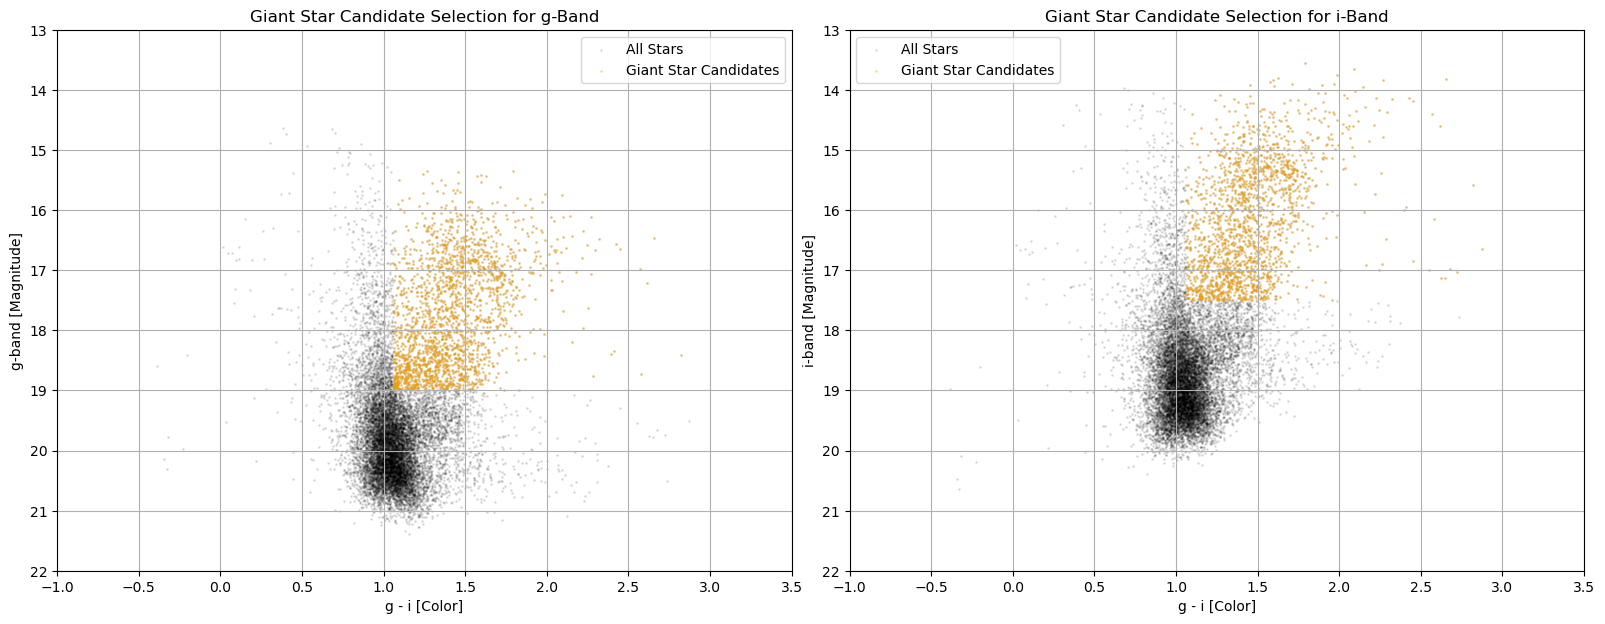

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot CMD for g-mag on the first subplot (ax1) ---
ax1.scatter(gmi, g, s=1, color='black', alpha=0.1, label = 'All Stars')
ax1.scatter(giant_colors_g, giant_magnitudes_g, s = 1, color = 'orange', alpha = 0.3, label = 'Giant Star Candidates')

ax1.set_xlim(-1, 3.5)
ax1.invert_yaxis() # Brighter stars at the top
ax1.set_ylim(22, 13)

ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax1.set_ylabel(f"{magnitude_band}-band [Magnitude]")
ax1.set_title("Giant Star Candidate Selection for g-Band")
ax1.grid(True)

ax1.legend(loc = 'best')

# --- Plot CMD for i-mag on the second subplot (ax2) ---
ax2.scatter(gmi, i, s=1, color='black', alpha=0.1, label = 'All Stars')
ax2.scatter(giant_colors_i, giant_magnitudes_i, s = 1, color = 'orange', alpha = 0.3, label = 'Giant Star Candidates')

ax2.set_xlim(-1, 3.5)
ax2.invert_yaxis() # Brighter stars at the top
ax2.set_ylim(22, 13)

ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax2.set_ylabel(f"{color_band_2}-band [Magnitude]") 
ax2.set_title("Giant Star Candidate Selection for i-Band")
ax2.grid(True)

ax2.legend(loc = 'best')

plt.show()

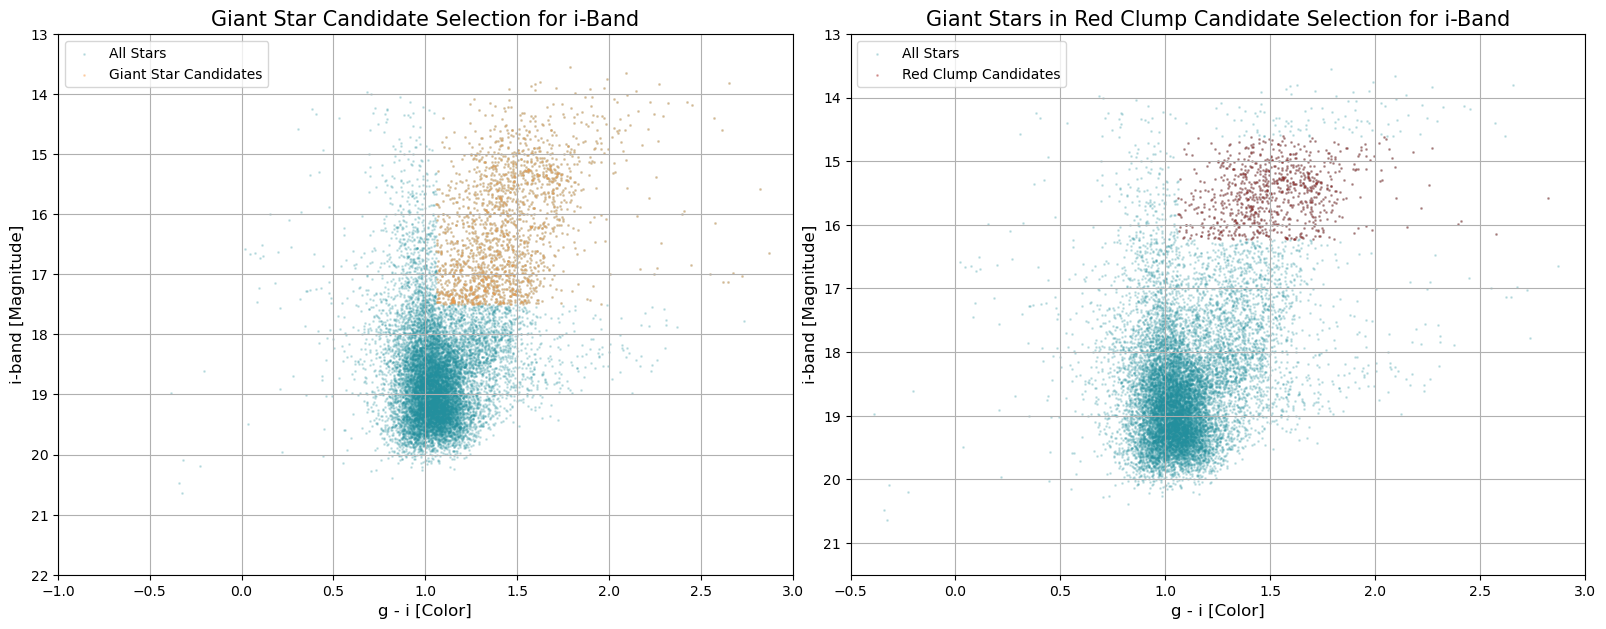

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot CMD for g-mag on the first subplot (ax1) ---
ax1.scatter(gmi, i, s=1, color= '#238F9D', alpha=0.2, label='All Stars')
ax1.scatter(giant_colors_i, giant_magnitudes_i, s=1, color='#FD9A44', alpha=0.3, label='Giant Star Candidates')

ax1.set_xlim(-1, 3)
ax1.set_ylim(13, 22)
ax1.invert_yaxis()

ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax1.set_ylabel(f"{color_band_2}-band [Magnitude]", fontsize = 12)
ax1.set_title("Giant Star Candidate Selection for i-Band", fontsize = 15)

ax1.grid(True)
ax1.legend(loc = 'best')

# --- Plot CMD for z-mag on the second subplot (ax2) ---
ax2.scatter(gmi, i, s=1, color='#238F9D', alpha=0.2, label = 'All Stars')
ax2.scatter(clump_colors_i, clump_magnitudes_i, s = 1, color = '#A01813', alpha = 0.3, label = 'Red Clump Candidates')

ax2.set_xlim(-0.5, 3)
ax2.invert_yaxis() # Brighter stars at the top
ax2.set_ylim(21.5, 13)

ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax2.set_ylabel(f"{color_band_2}-band [Magnitude]", fontsize = 12) 
ax2.set_title("Giant Stars in Red Clump Candidate Selection for i-Band", fontsize = 15)
ax2.grid(True)

ax2.legend(loc = 'best')

plt.show()

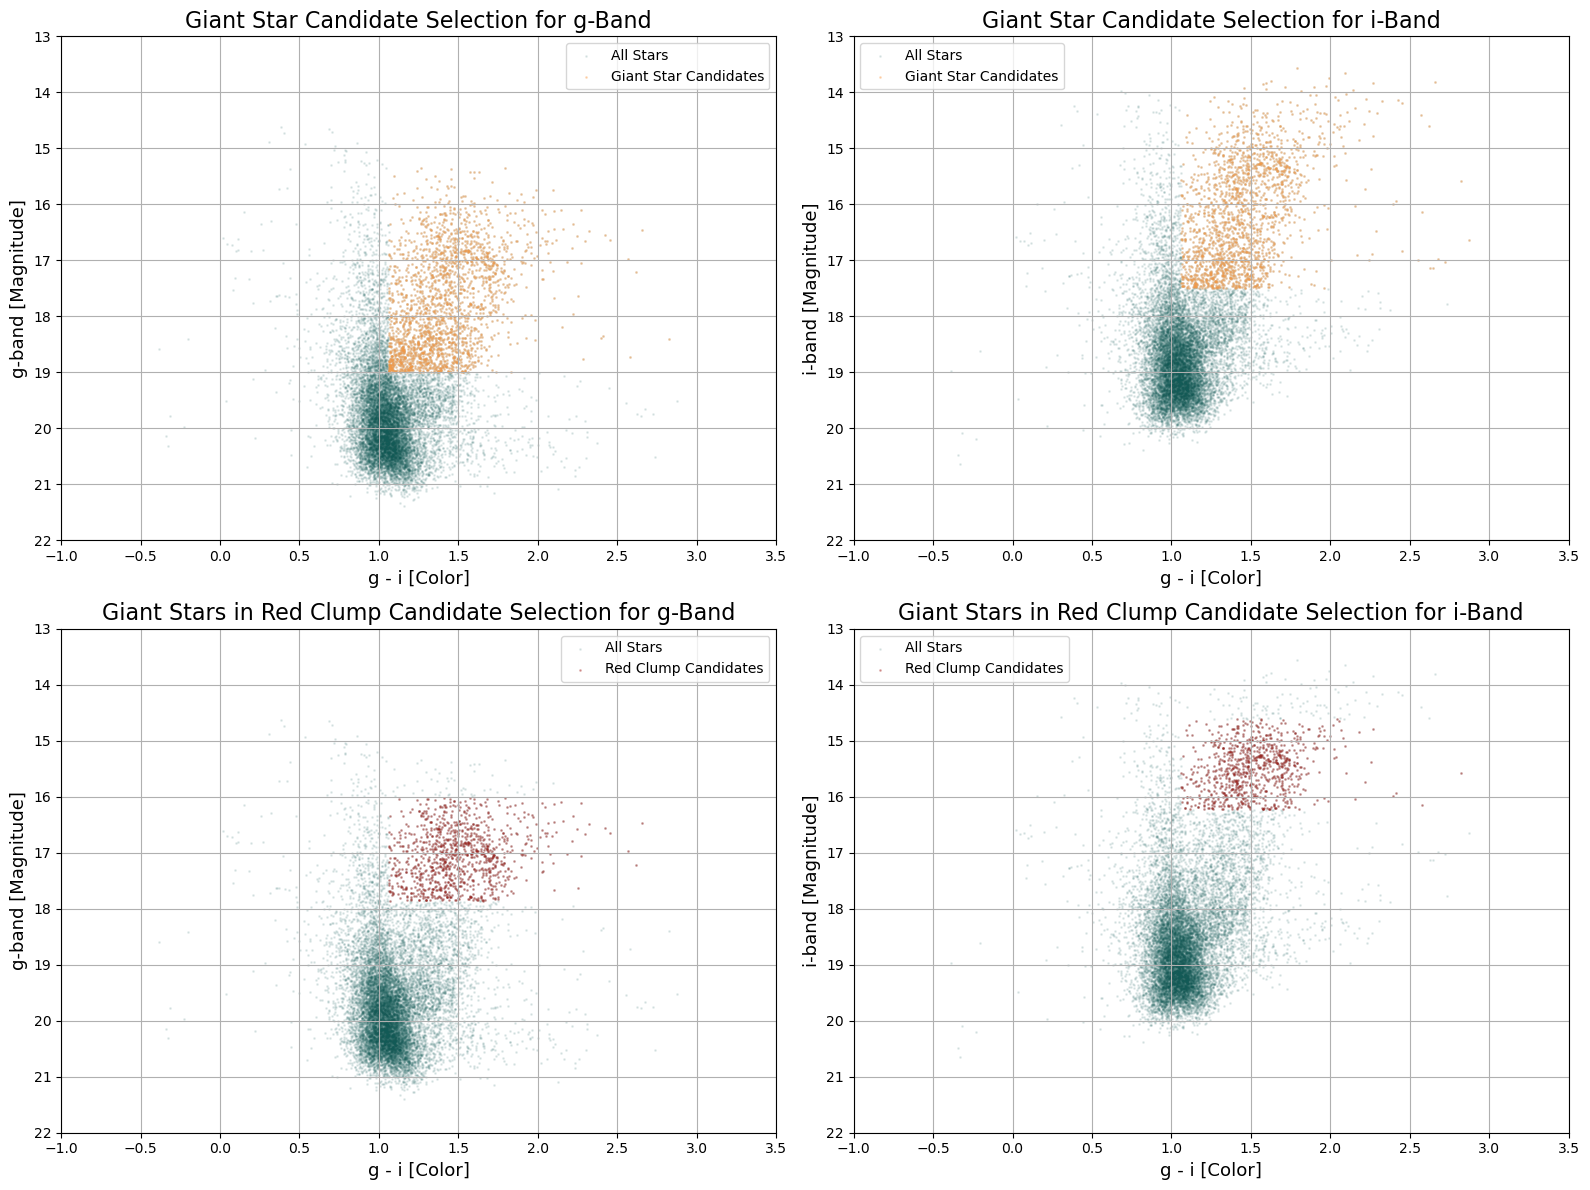

In [57]:
# Create one figure with 2 rows × 2 columns, each row height = 6
fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(2, 2, height_ratios=[6, 6])

# === Top-left: Giant star candidates (g-band) ===
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(gmi, g, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax1.scatter(giant_colors_g, giant_magnitudes_g, s=1, color='#FD9A44', alpha=0.3, label='Giant Star Candidates')
ax1.set_xlim(-1, 3.5)
ax1.set_ylim(13, 22)
ax1.invert_yaxis()
ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 13)
ax1.set_ylabel(f"{magnitude_band}-band [Magnitude]", fontsize = 13)
ax1.set_title("Giant Star Candidate Selection for g-Band", fontsize = 16)
ax1.grid(True)
ax1.legend(loc='best')

# === Top-right: Giant star candidates (i-band) ===
ax2 = fig.add_subplot(gs[0, 1])
ax2.scatter(gmi, i, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax2.scatter(giant_colors_i, giant_magnitudes_i, s=1, color='#FD9A44', alpha=0.3, label='Giant Star Candidates')
ax2.set_xlim(-1, 3.5)
ax2.set_ylim(13, 22)
ax2.invert_yaxis()
ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 13)
ax2.set_ylabel(f"{color_band_2}-band [Magnitude]", fontsize = 13)
ax2.set_title("Giant Star Candidate Selection for i-Band", fontsize = 16)
ax2.grid(True)
ax2.legend(loc='best')

# === Bottom-left: Red clump candidates (g-band) ===
ax3 = fig.add_subplot(gs[1, 0])
ax3.scatter(gmi, g, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax3.scatter(clump_colors_g, clump_magnitudes_g, s=1, color='#A01813', alpha=0.3, label='Red Clump Candidates')
ax3.set_xlim(-1, 3.5)
ax3.set_ylim(13, 22)
ax3.invert_yaxis()
ax3.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 13)
ax3.set_ylabel(f"{magnitude_band}-band [Magnitude]", fontsize = 13)
ax3.set_title("Giant Stars in Red Clump Candidate Selection for g-Band", fontsize = 16)
ax3.grid(True)
ax3.legend(loc='best')

# === Bottom-right: Red clump candidates (i-band) ===
ax4 = fig.add_subplot(gs[1, 1])
ax4.scatter(gmi, i, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax4.scatter(clump_colors_i, clump_magnitudes_i, s=1, color='#A01813', alpha=0.3, label='Red Clump Candidates')
ax4.set_xlim(-1, 3.5)
ax4.set_ylim(13, 22)
ax4.invert_yaxis()
ax4.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 13)
ax4.set_ylabel(f"{color_band_2}-band [Magnitude]", fontsize = 13)
ax4.set_title("Giant Stars in Red Clump Candidate Selection for i-Band", fontsize = 16)
ax4.grid(True)
ax4.legend(loc='best')

plt.tight_layout()
plt.savefig('figures/gi_cmd_sub4.png')
plt.show()

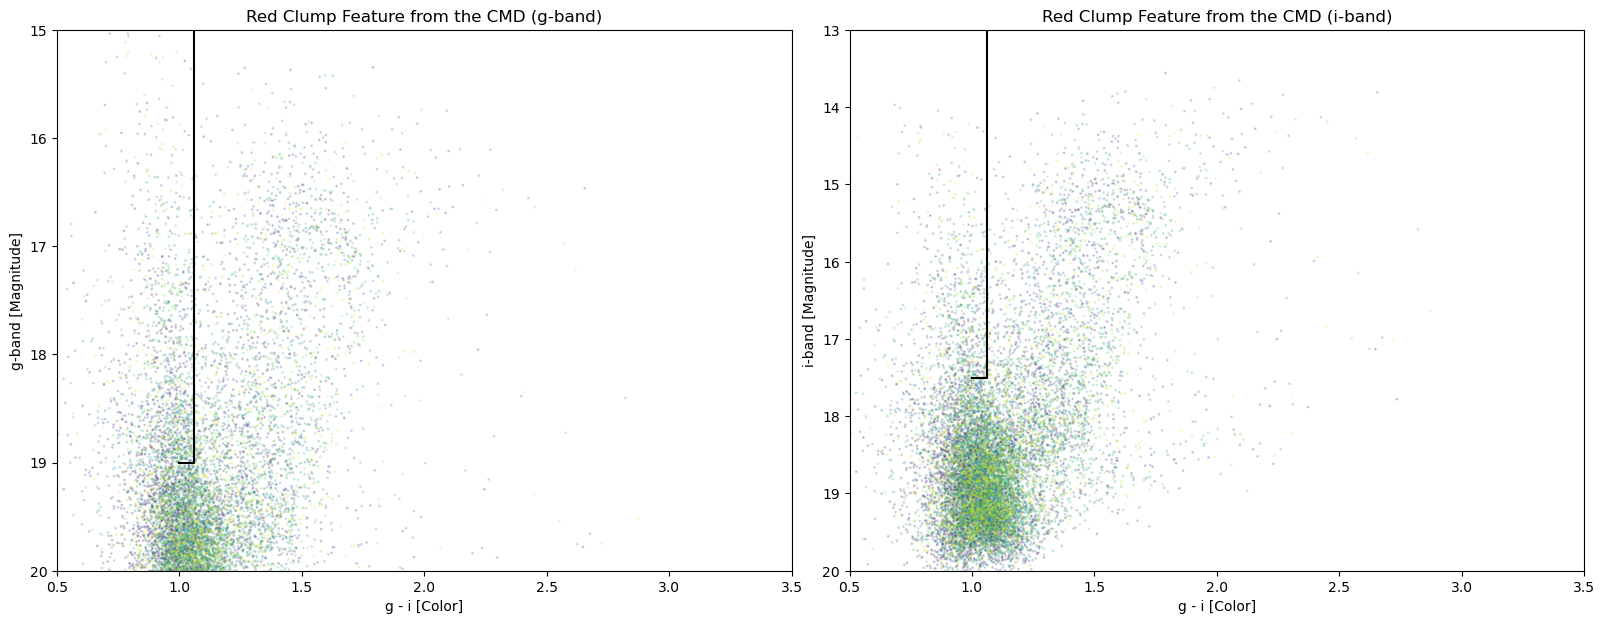

In [61]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot Red Clump feature from CMD for g-mag on the first subplot (ax1) ---
ax1.scatter(gmi, g, c = ra_g, s = 1, alpha = 0.2, rasterized = True)
ax1.plot([default_color_cut, default_color_cut, color_range_max], [13.0, magnitude_cut_g, magnitude_cut_g], 'k-')

ax1.set_xlim(0.5, 3.5)
ax1.set_ylim(20, 15)

ax1.set_title('Red Clump Feature from the CMD (g-band)')
ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax1.set_ylabel(f"{magnitude_band}-band [Magnitude]")

# --- Plot Red Clump feature from CMD for i-mag on the second subplot (ax2) ---
ax2.scatter(gmi, i, c = ra_i, s = 1, alpha = 0.2, rasterized = True)
ax2.plot([default_color_cut, default_color_cut, color_range_max], [13.0, magnitude_cut_i, magnitude_cut_i], 'k-')

ax2.set_xlim(0.5, 3.5)
ax2.set_ylim(20, 13)

ax2.set_title('Red Clump Feature from the CMD (i-band)')
ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax2.set_ylabel(f"{color_band_2}-band [Magnitude]")

plt.show()

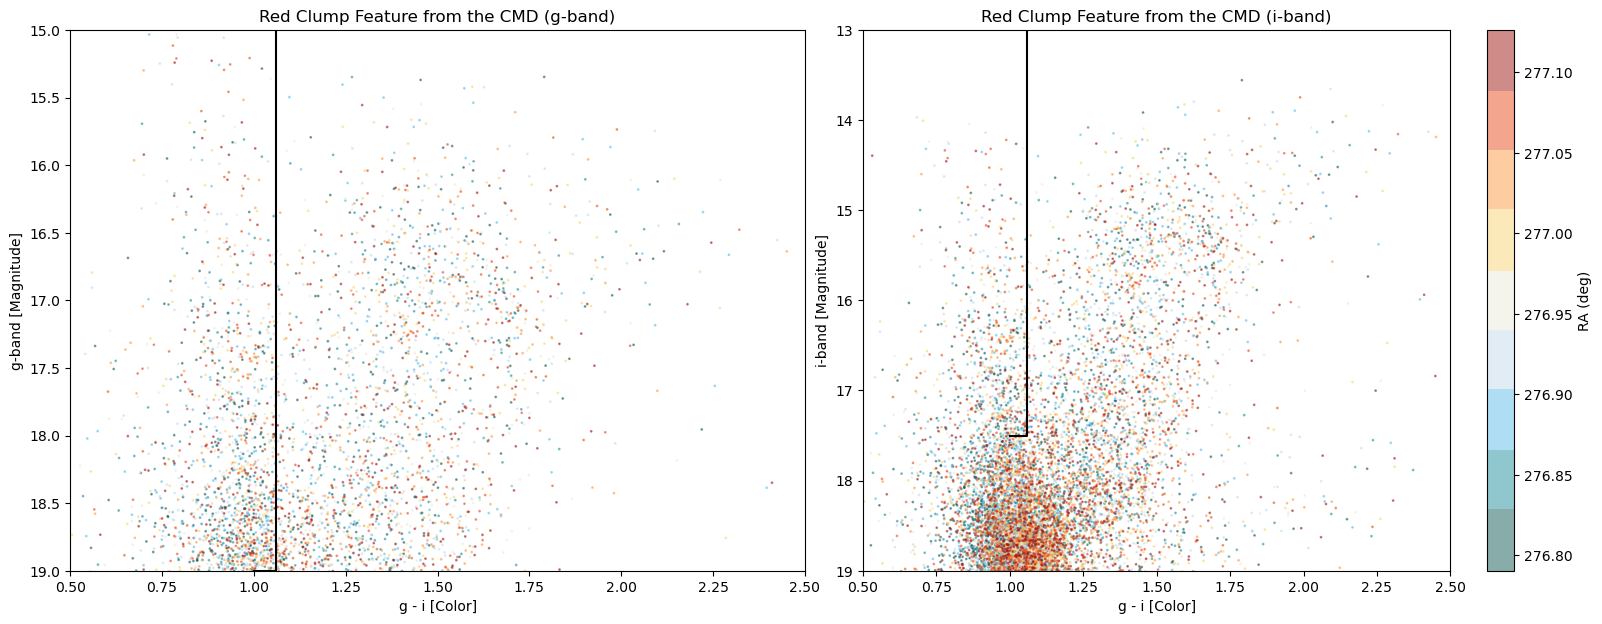

In [83]:
# Get the custom colormap
nightfall_cmap = tol_cmap('nightfall_discrete')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot Red Clump feature from CMD for r-mag on the first subplot (ax1) ---
sc = ax1.scatter(
    gmi,
    g,
    c = ra_g,
    cmap = nightfall_cmap,  # <-- apply the color map here
    s = 1,
    alpha = 0.5,
    rasterized = True
)

ax1.plot([default_color_cut, default_color_cut, color_range_max],
         [13.0, magnitude_cut_g, magnitude_cut_g], 'k-')

ax1.set_xlim(0.5, 2.5)
ax1.set_ylim(19, 15)

ax1.set_title('Red Clump Feature from the CMD (g-band)')
ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax1.set_ylabel(f"{magnitude_band}-band [Magnitude]")

# --- Plot Red Clump feature from CMD for z-mag on the second subplot (ax2) ---
sc_2 = ax2.scatter(
    gmi,
    i,
    c = ra_g,
    cmap = nightfall_cmap,  # <-- apply the color map here
    s = 1,
    alpha = 0.5,
    rasterized = True
)

ax2.plot([default_color_cut, default_color_cut, color_range_max],
         [13.0, magnitude_cut_i, magnitude_cut_i], 'k-')

ax2.set_xlim(0.5, 2.5)
ax2.set_ylim(19, 13)

ax2.set_title('Red Clump Feature from the CMD (i-band)')
ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax2.set_ylabel(f"{color_band_2}-band [Magnitude]")

plt.colorbar(sc_2, label='RA (deg)')
plt.show()

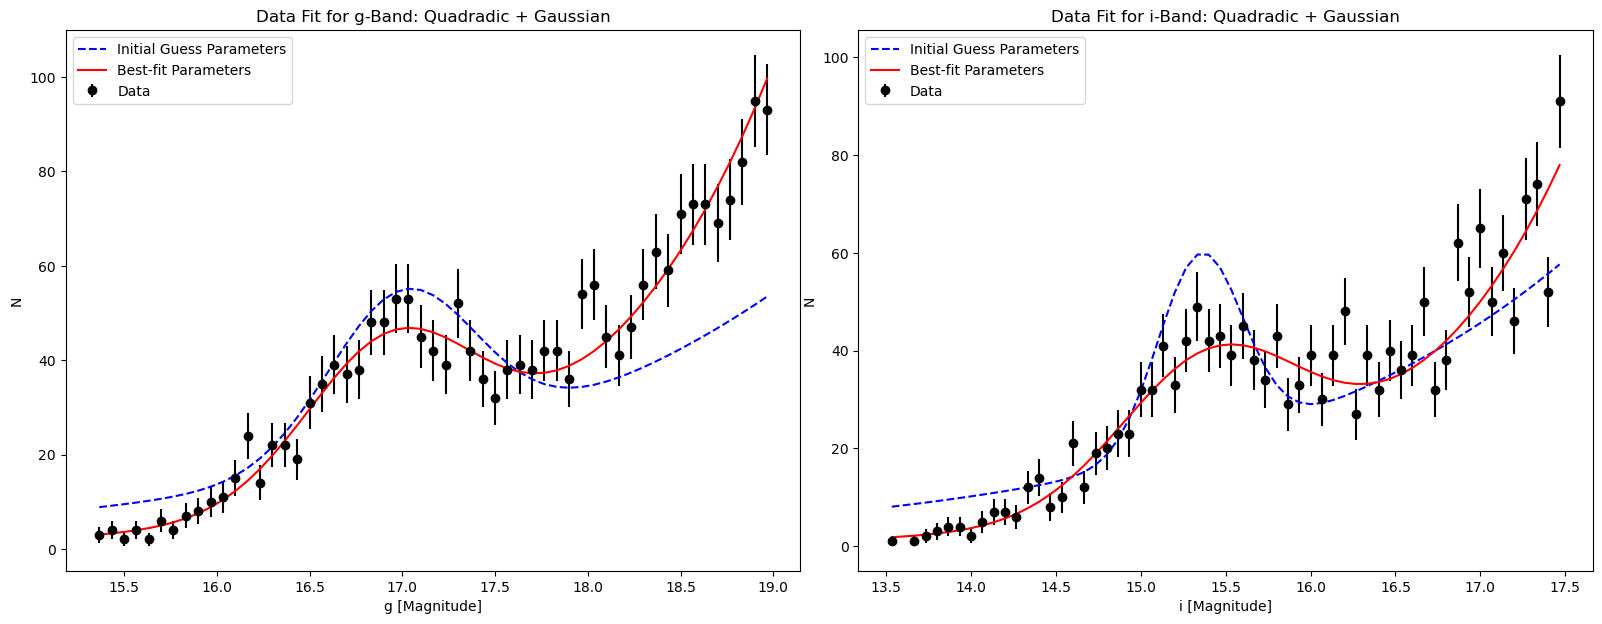

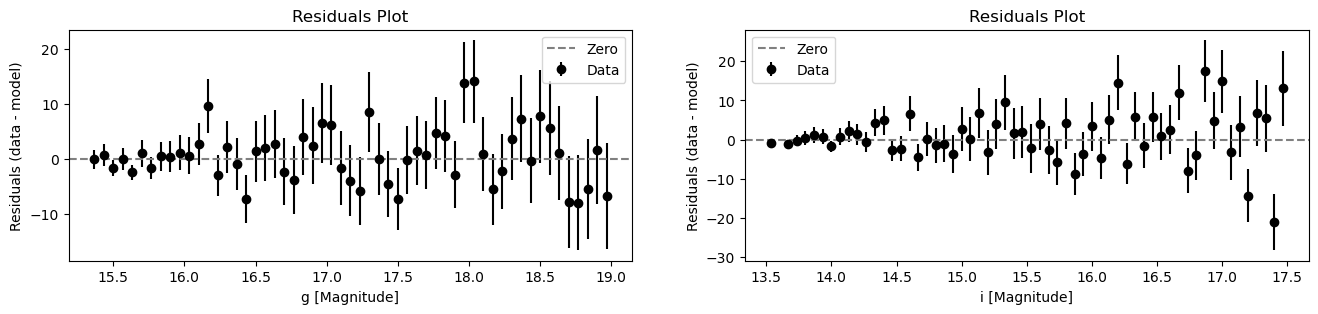

g_rc = 16.939 ± 0.029, sigma_rc_g =  0.462 ± 0.037, A_g = 1.102 ± 0.029
i_rc = 15.419 ± 0.043, sigma_rc_g =  0.540 ± 0.053, A_i = 0.576 ± 0.043


In [85]:
initial_guess_2 = [20.0, 0.5, 17.0, 35.0, 0.4]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot rcmodel Data Fit of Giant Stars for g-mag on the first subplot (ax1) ---
ax1.errorbar(bin_centers_m0g, hist_counts_m0g, yerr = np.sqrt(hist_counts_m0g), fmt = 'ko', label = 'Data') 
ax1.plot(bin_centers_m0g, rcmodel_g(bin_centers_m0g, *initial_guess_2), 'b--', label = 'Initial Guess Parameters')
ax1.plot(bin_centers_m0g, rcmodel_g(bin_centers_m0g, *par_0g), 'r-', label = 'Best-fit Parameters')

ax1.set_xlabel(f"{magnitude_band} [Magnitude]")
ax1.set_ylabel(f"N")
ax1.set_title('Data Fit for g-Band: Quadradic + Gaussian')

ax1.legend(loc='best')

# --- Plot rcmodel Data Fit of Giant Stars CMD for i-mag on the second subplot (ax2) ---
ax2.errorbar(bin_centers_m0i, hist_counts_m0i, yerr = np.sqrt(hist_counts_m0i), fmt = 'ko', label = 'Data') 

ax2.plot(bin_centers_m0i, rcmodel_i(bin_centers_m0i, *initial_guess_4), 'b--', label = 'Initial Guess Parameters')
ax2.plot(bin_centers_m0i, rcmodel_i(bin_centers_m0i, *par_0i), 'r-', label = 'Best-fit Parameters')

ax2.set_xlabel(f"{color_band_2} [Magnitude]")
ax2.set_ylabel(f"N")
ax2.set_title('Data Fit for i-Band: Quadradic + Gaussian')

ax2.legend(loc='best')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 3)) # Increased width for side-by-side
# plt.tight_layout()

# --- Plot residuals for g-mag on the first subplot (ax1) ---
# Compute residuals
model_vals_0g = rcmodel_g(bin_centers_m0g, *par_0g)
residuals_0g = hist_counts_m0g - model_vals_0g

ax1.errorbar(bin_centers_m0g, residuals_0g, yerr = np.sqrt(hist_counts_m0g), fmt = 'ko', label = 'Data')
ax1.axhline(0, color ='gray', linestyle ='--', label = 'Zero')

ax1.set_xlabel(f"{magnitude_band} [Magnitude]")
ax1.set_ylabel('Residuals (data - model)')
ax1.set_title('Residuals Plot')

ax1.legend(loc = 'best')

# --- Plot residuals for i-mag on the second subplot (ax2) ---
model_vals_0i = rcmodel_i(bin_centers_m0i, *par_0i)
residuals_0i = hist_counts_m0i - model_vals_0i

ax2.errorbar(bin_centers_m0i, residuals_0i, yerr = np.sqrt(hist_counts_m0i), fmt = 'ko', label = 'Data')
ax2.axhline(0, color ='gray', linestyle ='--', label = 'Zero')

ax2.set_xlabel(f"{color_band_2} [Magnitude]")
ax2.set_ylabel('Residuals (data - model)')
ax2.set_title('Residuals Plot')

ax2.legend(loc = 'best')
plt.show()

print(
    f"{magnitude_band}_rc = {par_0g[2]:6.3f} ± {np.sqrt(cov_0g[2, 2]):5.3f}, "
    f"sigma_rc_{magnitude_band} = {par_0g[4]:6.3f} ± {np.sqrt(cov_0g[4, 4]):5.3f}, "
    f"A_{magnitude_band} = {par_0g[2] - clumpmag0_g:5.3f} ± {np.sqrt(cov_0g[2, 2]):5.3f}"
)

print(
    f"{color_band_2}_rc = {par_0i[2]:6.3f} ± {np.sqrt(cov_0i[2, 2]):5.3f}, "
    f"sigma_rc_{magnitude_band} = {par_0i[4]:6.3f} ± {np.sqrt(cov_0i[4, 4]):5.3f}, "
    f"A_{color_band_2} = {par_0i[2] - clumpmag0_i:5.3f} ± {np.sqrt(cov_0i[2, 2]):5.3f}"
)

/var/folders/zz/w7p4t48s04983q5t6t1njc8m0000gn/T/ipykernel_29689/1319627317.py:13: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax1.errorbar(bin_centers_m0g, hist_counts_m0g, yerr=np.sqrt(hist_counts_m0g), fmt='o', color = '#125A56', marker = 'o',
/var/folders/zz/w7p4t48s04983q5t6t1njc8m0000gn/T/ipykernel_29689/1319627317.py:25: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax2.errorbar(bin_centers_m0i, hist_counts_m0i, yerr=np.sqrt(hist_counts_m0i), fmt='o', color = '#125A56', marker = 'o',
/var/folders/zz/w7p4t48s04983q5t6t1njc8m0000gn/T/ipykernel_29689/1319627317.py:37: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax3.errorbar(bin_centers_m0g

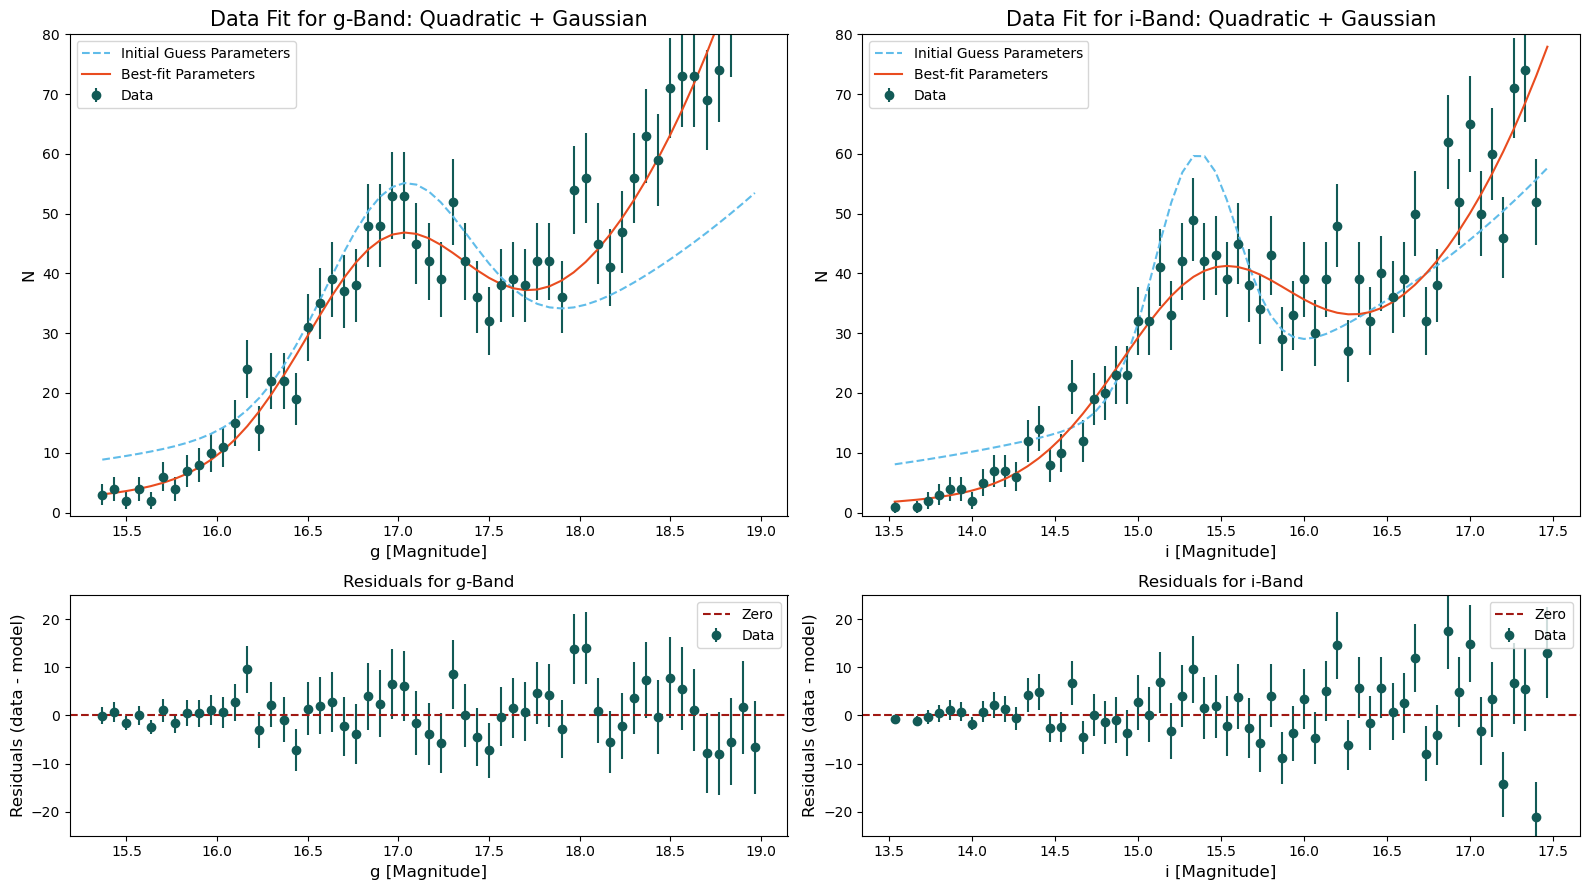

In [87]:
# Compute residuals
model_vals_0g = rcmodel_g(bin_centers_m0g, *par_0g)
residuals_0g = hist_counts_m0g - model_vals_0g
model_vals_0i = rcmodel_i(bin_centers_m0i, *par_0i)
residuals_0i = hist_counts_m0i - model_vals_0i

# Create one combined figure
fig = plt.figure(figsize=(16, 9))
gs = gridspec.GridSpec(2, 2, height_ratios=[6, 3])

# === Top-left: g-band data fit ===
ax1 = fig.add_subplot(gs[0, 0])
ax1.errorbar(bin_centers_m0g, hist_counts_m0g, yerr=np.sqrt(hist_counts_m0g), fmt='o', color = '#125A56', marker = 'o', 
             label='Data') 
ax1.plot(bin_centers_m0g, rcmodel_g(bin_centers_m0g, *initial_guess_2), '#60BCE9', linestyle = '--', label='Initial Guess Parameters')
ax1.plot(bin_centers_m0g, rcmodel_g(bin_centers_m0g, *par_0g), '#E94C1F', label='Best-fit Parameters')
ax1.set_ylim(-0.5, 80)
ax1.set_xlabel(f"{magnitude_band} [Magnitude]", fontsize = 12)
ax1.set_ylabel("N", fontsize = 12)
ax1.set_title("Data Fit for g-Band: Quadratic + Gaussian", fontsize = 15)
ax1.legend(loc='best')

# === Top-right: i-band data fit ===
ax2 = fig.add_subplot(gs[0, 1])
ax2.errorbar(bin_centers_m0i, hist_counts_m0i, yerr=np.sqrt(hist_counts_m0i), fmt='o', color = '#125A56', marker = 'o',
             label='Data') 
ax2.plot(bin_centers_m0i, rcmodel_i(bin_centers_m0i, *initial_guess_4), '#60BCE9', linestyle = '--', label='Initial Guess Parameters')
ax2.plot(bin_centers_m0i, rcmodel_i(bin_centers_m0i, *par_0i), '#E94C1F', label='Best-fit Parameters')
ax2.set_ylim(-0.5, 80)
ax2.set_xlabel(f"{color_band_2} [Magnitude]", fontsize = 12)
ax2.set_ylabel("N", fontsize = 12)
ax2.set_title("Data Fit for i-Band: Quadratic + Gaussian", fontsize = 15)
ax2.legend(loc='best')

# === Bottom-left: g-band residuals ===
ax3 = fig.add_subplot(gs[1, 0])
ax3.errorbar(bin_centers_m0g, residuals_0g, yerr=np.sqrt(hist_counts_m0g), fmt='o', color = '#125A56', marker = 'o', 
             label='Data')
ax3.axhline(0, color='#A01813',linestyle='--', label='Zero')
ax3.set_ylim(-25, 25)
ax3.set_xlabel(f"{magnitude_band} [Magnitude]", fontsize = 12)
ax3.set_ylabel("Residuals (data - model)", fontsize =12)
ax3.set_title("Residuals for g-Band")
ax3.legend(loc='best')

# === Bottom-right: i-band residuals ===
ax4 = fig.add_subplot(gs[1, 1])
ax4.errorbar(bin_centers_m0i, residuals_0i, yerr=np.sqrt(hist_counts_m0i), fmt='o', color = '#125A56', marker = 'o', 
             label='Data')
ax4.axhline(0, color='#A01813', linestyle='--', label='Zero')
ax4.set_ylim(-25, 25)
ax4.set_xlabel(f"{color_band_2} [Magnitude]", fontsize = 12)
ax4.set_ylabel("Residuals (data - model)", fontsize = 12)
ax4.set_title("Residuals for i-Band")
ax4.legend(loc='best')

plt.tight_layout()
plt.savefig('figures/gi_rcfit_sub4.png')
plt.show()

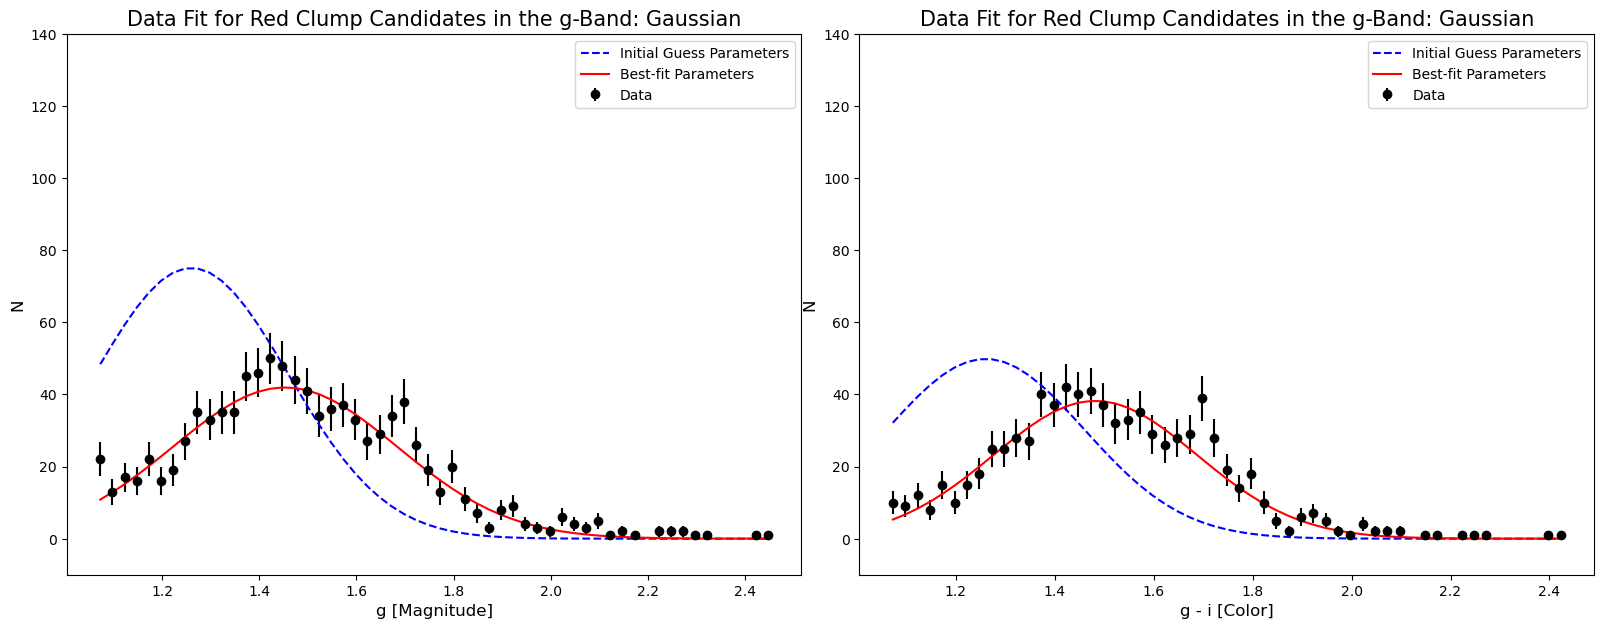

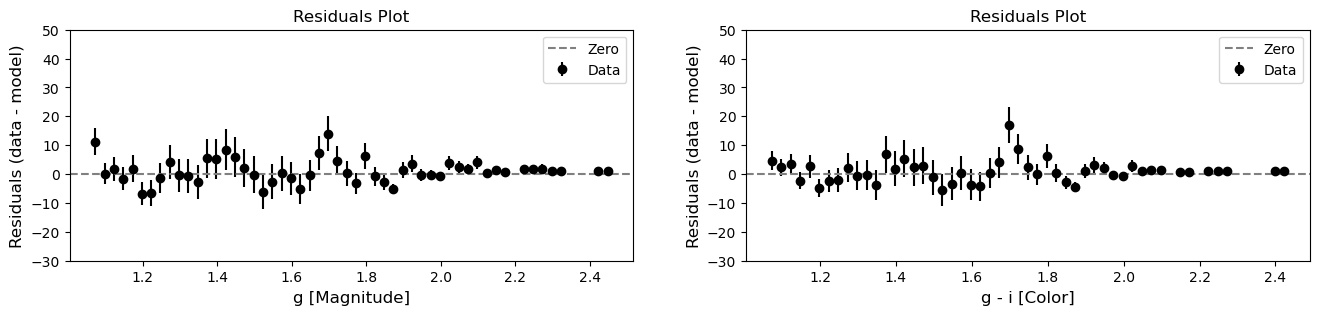

(g-i)_g = 1.453 ± 0.010,\
      σ_(g-i)_g = 0.231 ± 0.009
(g-i)_i = 1.482 ± 0.009,\
      σ_(g-i)_i = 0.206 ± 0.007


In [121]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot cgauss Data Fit of Giant Stars in the Red Clump for g-mag on the first subplot (ax1) ---
ax1.errorbar(bin_centers_m1g, hist_counts_m1g, yerr = np.sqrt(hist_counts_m1g), fmt = 'ko', label = 'Data') 
ax1.plot(bin_centers_m1g, cgauss(bin_centers_m1g, *initial_guess_1), 'b--', label = 'Initial Guess Parameters')
ax1.plot(bin_centers_m1g, cgauss(bin_centers_m1g, *par_1g), 'r-', label = 'Best-fit Parameters')

ax1.set_ylim(-10, 140)

ax1.set_xlabel(f"{magnitude_band} [Magnitude]", fontsize = 12)
ax1.set_ylabel(f"N", fontsize = 12)
ax1.set_title('Data Fit for Red Clump Candidates in the g-Band: Gaussian', fontsize = 15)

ax1.legend(loc='best')

# --- Plot cgauss Data Fit of Giant Stars CMD in the Red Clump for i-mag on the second subplot (ax2) ---
ax2.errorbar(bin_centers_m1i, hist_counts_m1i, yerr = np.sqrt(hist_counts_m1i), fmt = 'ko', label = 'Data') 
ax2.plot(bin_centers_m1i, cgauss(bin_centers_m1i, *initial_guess_3), 'b--', label = 'Initial Guess Parameters')
ax2.plot(bin_centers_m1i, cgauss(bin_centers_m1i, *par_1i), 'r-', label = 'Best-fit Parameters')

ax2.set_ylim(-10, 140)
ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax2.set_ylabel(f"N", fontsize = 12)
ax2.set_title('Data Fit for Red Clump Candidates in the g-Band: Gaussian', fontsize = 15)

ax2.legend(loc='best')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 3)) # Increased width for side-by-side
# plt.tight_layout()

# --- Plot residuals for g-mag on the first subplot (ax1) ---
# Compute residuals
model_vals_1g = cgauss(bin_centers_m1g, *par_1g)
residuals_1g = hist_counts_m1g - model_vals_1g

ax1.errorbar(bin_centers_m1g, residuals_1g, yerr = np.sqrt(hist_counts_m1g), fmt = 'ko', label = 'Data')
ax1.axhline(0, color ='gray', linestyle ='--', label = 'Zero')

ax1.set_ylim(-30, 50)
ax1.set_xlabel(f"{magnitude_band} [Magnitude]", fontsize = 12)
ax1.set_ylabel('Residuals (data - model)', fontsize = 12)
ax1.set_title('Residuals Plot')

ax1.legend(loc = 'best')

# --- Plot residuals for i-mag on the second subplot (ax2) ---
# Compute residuals
model_vals_1i = cgauss(bin_centers_m1i, *par_1i)
residuals_1i = hist_counts_m1i - model_vals_1i

ax2.errorbar(bin_centers_m1i, residuals_1i, yerr = np.sqrt(hist_counts_m1i), fmt = 'ko', label = 'Data')
ax2.axhline(0, color ='gray', linestyle ='--', label = 'Zero')

ax2.set_ylim(-30, 50)

ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax2.set_ylabel('Residuals (data - model)', fontsize = 12)
ax2.set_title('Residuals Plot')

ax2.legend(loc = 'best')
plt.show()

print(rf"({color_band_1}-{color_band_2})_{magnitude_band} = {par_1g[1]:.3f} ± {np.sqrt(cov_1g[1,1]):.3f},\
      σ_({color_band_1}-{color_band_2})_{magnitude_band} = {par_1g[2]:.3f} ± {np.sqrt(cov_1g[2,2]):.3f}")

print(rf"({color_band_1}-{color_band_2})_{color_band_2} = {par_1i[1]:.3f} ± {np.sqrt(cov_1i[1,1]):.3f},\
      σ_({color_band_1}-{color_band_2})_{color_band_2} = {par_1i[2]:.3f} ± {np.sqrt(cov_1i[2,2]):.3f}")

/var/folders/zz/w7p4t48s04983q5t6t1njc8m0000gn/T/ipykernel_29689/3470758641.py:13: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax1.errorbar(bin_centers_m1g, hist_counts_m1g, yerr = np.sqrt(hist_counts_m1g), fmt = 'o',color = '#125A56', marker = 'o', label = 'Data')
/var/folders/zz/w7p4t48s04983q5t6t1njc8m0000gn/T/ipykernel_29689/3470758641.py:24: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax2.errorbar(bin_centers_m1i, hist_counts_m1i, yerr=np.sqrt(hist_counts_m1i), fmt='o', color = '#125A56', marker = 'o', label='Data')
/var/folders/zz/w7p4t48s04983q5t6t1njc8m0000gn/T/ipykernel_29689/3470758641.py:35: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedenc

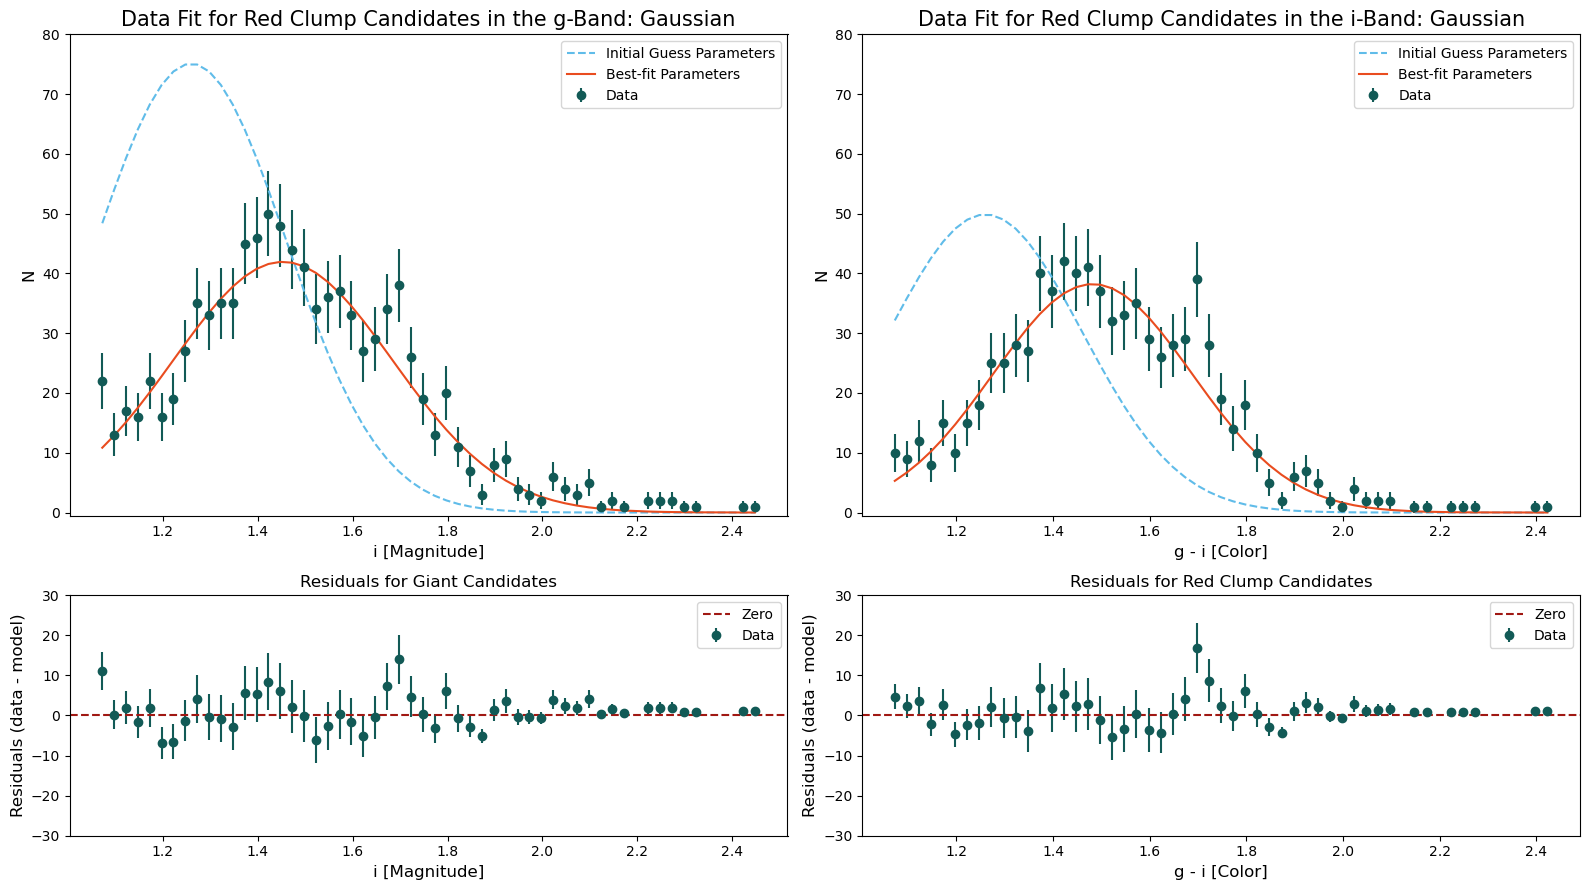

In [125]:
# === Compute residuals ===
model_vals_0i = rcmodel_i(bin_centers_m0i, *par_0i)
residuals_0i = hist_counts_m0i - model_vals_0i

model_vals_1i = cgauss(bin_centers_m1i, *par_1i)
residuals_1i = hist_counts_m1i - model_vals_1i

fig = plt.figure(figsize=(16, 9))
gs = gridspec.GridSpec(2, 2, height_ratios=[6, 3])

# === Top-left ===
ax1 = fig.add_subplot(gs[0, 0])
ax1.errorbar(bin_centers_m1g, hist_counts_m1g, yerr = np.sqrt(hist_counts_m1g), fmt = 'o',color = '#125A56', marker = 'o', label = 'Data') 
ax1.plot(bin_centers_m1g, cgauss(bin_centers_m1g, *initial_guess_1), '#60BCE9', linestyle = '--', label = 'Initial Guess Parameters')
ax1.plot(bin_centers_m1g, cgauss(bin_centers_m1g, *par_1g), '#E94C1F', label = 'Best-fit Parameters')
ax1.set_ylim(-0.5, 80)
ax1.set_xlabel(f"{color_band_2} [Magnitude]", fontsize = 12)
ax1.set_ylabel("N", fontsize = 12)
ax1.set_title('Data Fit for Red Clump Candidates in the g-Band: Gaussian', fontsize = 15)
ax1.legend(loc='best')

# === Top-right ===
ax2 = fig.add_subplot(gs[0, 1])
ax2.errorbar(bin_centers_m1i, hist_counts_m1i, yerr=np.sqrt(hist_counts_m1i), fmt='o', color = '#125A56', marker = 'o', label='Data') 
ax2.plot(bin_centers_m1i, cgauss(bin_centers_m1i, *initial_guess_3), '#60BCE9', linestyle = '--', label='Initial Guess Parameters')
ax2.plot(bin_centers_m1i, cgauss(bin_centers_m1i, *par_1i), '#E94C1F', label='Best-fit Parameters')
ax2.set_ylim(-0.5, 80)
ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax2.set_ylabel("N", fontsize = 12)
ax2.set_title("Data Fit for Red Clump Candidates in the i-Band: Gaussian", fontsize = 15)
ax2.legend(loc='best')

# === Bottom-left ===
ax3 = fig.add_subplot(gs[1, 0])
ax3.errorbar(bin_centers_m1g, residuals_1g, yerr=np.sqrt(hist_counts_m1g), fmt='o', color = '#125A56', marker = 'o', label='Data')
ax3.axhline(0, color='#A01813', linestyle='--', label='Zero')
ax3.set_ylim(-30, 30)
ax3.set_xlabel(f"{color_band_2} [Magnitude]", fontsize = 12)
ax3.set_ylabel("Residuals (data - model)", fontsize = 12)
ax3.set_title("Residuals for Giant Candidates", fontsize = 12)
ax3.legend(loc='best')

# === Bottom-right ===
ax4 = fig.add_subplot(gs[1, 1])
ax4.errorbar(bin_centers_m1i, residuals_1i, yerr=np.sqrt(hist_counts_m1i), fmt='o', color = '#125A56', marker = 'o', label='Data')
ax4.axhline(0, color='#A01813', linestyle='--', label='Zero')
ax4.set_ylim(-30, 30)
ax4.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax4.set_ylabel("Residuals (data - model)", fontsize = 12)
ax4.set_title("Residuals for Red Clump Candidates", fontsize = 12)
ax4.legend(loc='best')

plt.tight_layout()
plt.savefig('figures/gi_cgauss_sub4.png')
plt.show()

In [93]:
# === Calculate the 1D KDE for Giant and Clump Candidates ===
# Filter out extreme values (if any) to avoid over-smoothing
kde_giant_magnitudes_g = giant_magnitudes_g[(giant_magnitudes_g > 14) & (giant_magnitudes_g < 18)]
kde_giant_magnitudes_g = np.array(kde_giant_magnitudes_g, dtype=float)
kde_giant_magnitudes_g = kde_giant_magnitudes_g[np.isfinite(kde_giant_magnitudes_g)]

kde_clump_colors_g = clump_colors_g[(clump_colors_g > 0.5) & (clump_colors_g < 1.6)]
kde_clump_colors_g = np.array(kde_clump_colors_g, dtype=float)
kde_clump_colors_g = kde_clump_colors_g[np.isfinite(kde_clump_colors_g)]

# Fit KDE
kde_giant_g_mag = gaussian_kde(kde_giant_magnitudes_g)
kde_clump_gmi_col = gaussian_kde(kde_clump_colors_g)

# Evaluation grid
x_giant_g_mag = np.linspace(np.min(kde_giant_magnitudes_g), np.max(kde_giant_magnitudes_g), 200)
x_clump_gmi_col = np.linspace(np.min(kde_clump_colors_g), np.max(kde_clump_colors_g), 200)

# Evaluate KDE
kde_giant_g_mag_vals = kde_giant_g_mag(x_giant_g_mag)
kde_clump_gmi_col_vals = kde_clump_gmi_col(x_clump_gmi_col)

KDE Giant peak magnitude: 16.973
KDE Giant peak magnitude: 15.347
KDE Clump peak magnitude: 1.420
KDE Clump peak magnitude: 1.060


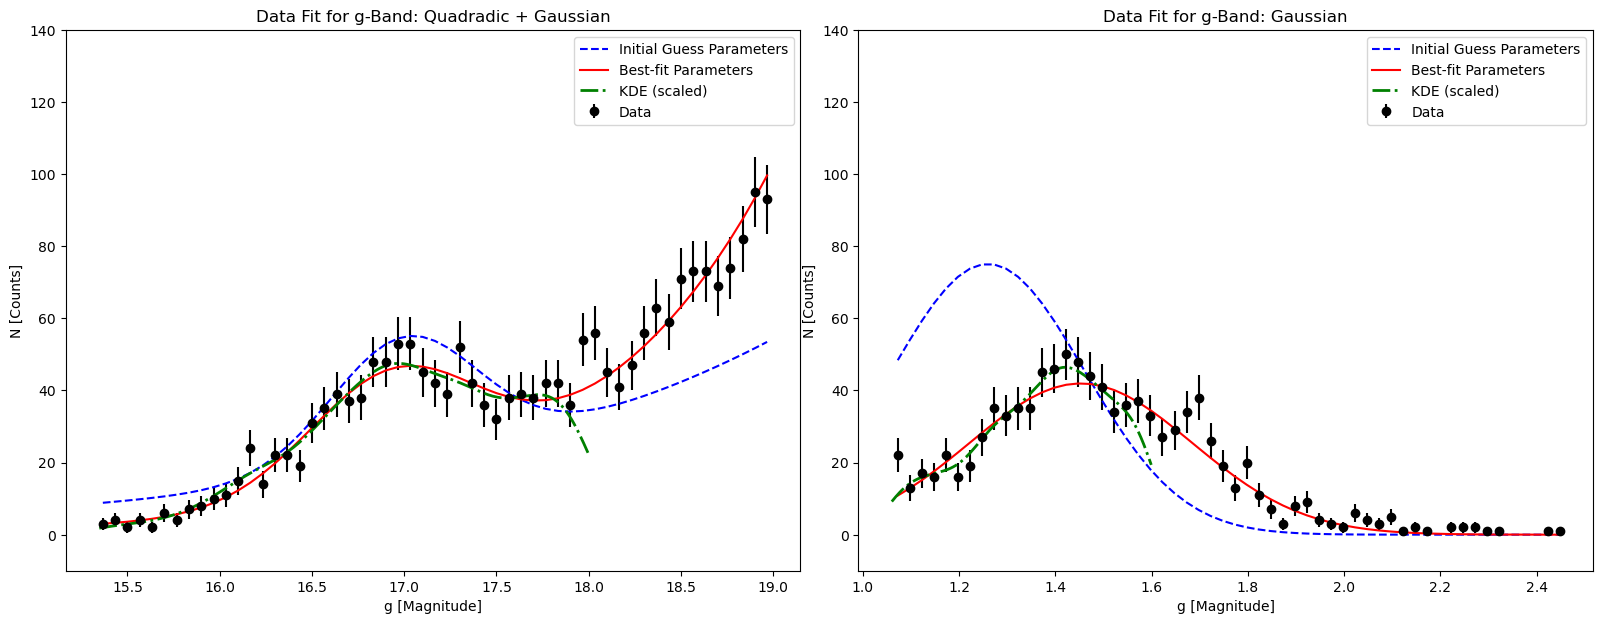

In [95]:
# Calculate the max and min magnitudes
peak_giant_max_ind = np.argmax(kde_giant_g_mag_vals)
peak_giant_max_kde = x_giant_g_mag[peak_giant_max_ind]
print(f"KDE Giant peak magnitude: {peak_giant_max_kde:.3f}")

peak_giant_min_ind = np.argmin(kde_giant_g_mag_vals)
peak_giant_min_kde = x_giant_g_mag[peak_giant_min_ind]
print(f"KDE Giant peak magnitude: {peak_giant_min_kde:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot rcmodel_g Data Fit of Giant Stars for g-mag on the first subplot (ax1) ---
ax1.errorbar(bin_centers_m0g, hist_counts_m0g, yerr = np.sqrt(hist_counts_m0g), fmt = 'ko', label = 'Data') 
ax1.plot(bin_centers_m0g, rcmodel_g(bin_centers_m0g, *initial_guess_2), 'b--', label = 'Initial Guess Parameters')
ax1.plot(bin_centers_m0g, rcmodel_g(bin_centers_m0g, *par_0g), 'r-', label = 'Best-fit Parameters')

# Scale KDE so it matches the historgrams vertical scale
bin_width_giant = bin_edges_giant_g[1] - bin_edges_giant_g[0]
kde_giant_g_mag_vals_scaled = kde_giant_g_mag_vals * len(kde_giant_magnitudes_g) * bin_width_giant
ax1.plot(x_giant_g_mag, kde_giant_g_mag_vals_scaled, 'g-.', lw = 2, label = 'KDE (scaled)')

ax1.set_ylim(-10, 140)

ax1.set_xlabel(f"{magnitude_band} [Magnitude]")
ax1.set_ylabel(f"N [Counts]")
ax1.set_title('Data Fit for g-Band: Quadradic + Gaussian')

ax1.legend(loc='best')

# Calculate the max and min magnitudes
peak_clump_max_ind = np.argmax(kde_clump_gmi_col_vals)
peak_clump_max_kde = x_clump_gmi_col[peak_clump_max_ind]
print(f"KDE Clump peak magnitude: {peak_clump_max_kde:.3f}")

peak_clump_min_ind = np.argmin(kde_clump_gmi_col_vals)
peak_clump_min_kde = x_clump_gmi_col[peak_clump_min_ind]
print(f"KDE Clump peak magnitude: {peak_clump_min_kde:.3f}")

# --- Plot cgauss Data Fit of Giant Stars in the Red Clump for g-mag on the first subplot (ax2) ---
ax2.errorbar(bin_centers_m1g, hist_counts_m1g, yerr = np.sqrt(hist_counts_m1g), fmt = 'ko', label = 'Data') 
ax2.plot(bin_centers_m1g, cgauss(bin_centers_m1g, *initial_guess_1), 'b--', label = 'Initial Guess Parameters')
ax2.plot(bin_centers_m1g, cgauss(bin_centers_m1g, *par_1g), 'r-', label = 'Best-fit Parameters')

# Scale KDE so it matches the historgrams vertical scale
bin_width_clump = bin_edges_clump_g[1] - bin_edges_clump_g[0]
kde_clump_gmi_col_vals_scaled = kde_clump_gmi_col_vals * len(kde_clump_colors_g) * bin_width_clump
ax2.plot(x_clump_gmi_col, kde_clump_gmi_col_vals_scaled, 'g-.', lw = 2, label = 'KDE (scaled)')

ax2.set_ylim(-10, 140)

ax2.set_xlabel(f"{magnitude_band} [Magnitude]")
ax2.set_ylabel(f"N [Counts]")
ax2.set_title('Data Fit for g-Band: Gaussian')

ax2.legend(loc='best')

plt.show()

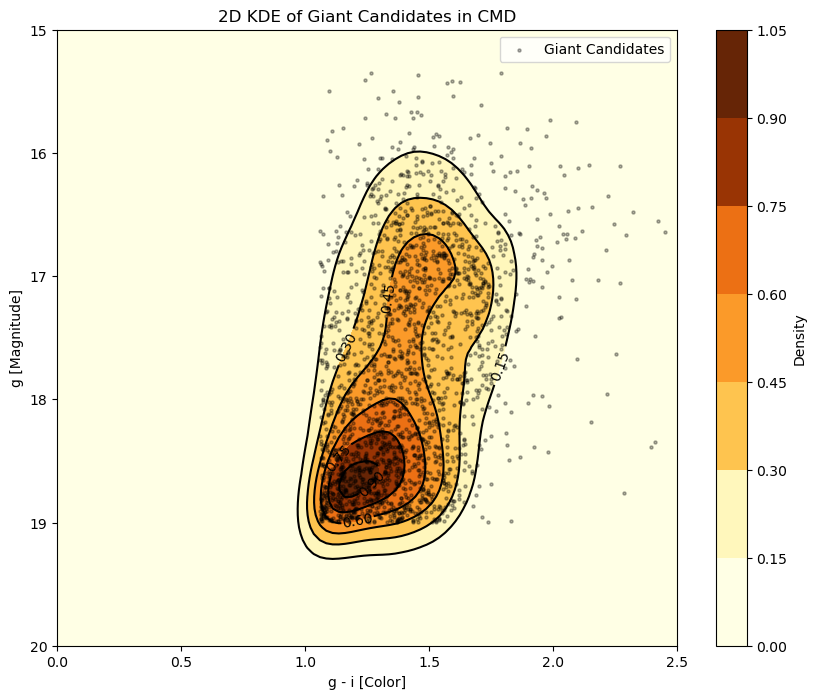

In [117]:
# === Calculate the 2D KDE for Giant and Red Clump Candidates ===
# Code Reference: https://stackoverflow.com/questions/30145957/plotting-2d-kernel-density-estimation-with-python and
 # Google Gemini

# Get the custom colormap
YlOrBr_cmap = tol_cmap('YlOrBr_discrete')

# --- 2D KDE for Giant Candidates ---
# Define x and y for the 2D KDE
x = giant_colors_g
y = giant_magnitudes_g

# Ensure that there is enough data for 2D KDE calculation (at least 2 poin ts)
if len(x) < 2 or len(y) < 2:
    print("Not enough data points for 2D KDE after filtering. Skipping 2D KDE plot.")
else:
    # Define the plot limits based on your data and CMD parameters
    xmin, xmax = 0, 2.5
    ymin, ymax = 15, 20

    # Peform the kernel density estimate
    xx, yy = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
    positions = np.vstack([xx.ravel(), yy.ravel()])
    
    # Stack your x and y data for the KDE calculation
    # print(f"Shape of x: {x.shape}")
    # print(f"Shape of y: {y.shape}")
    values = np.vstack([x, y])
    
    # Create the KDE object
    kernel = st.gaussian_kde(values)
    
    # Evaluate the KDE on the grid
    f = np.reshape(kernel(positions).T, xx.shape)

    # Plotting the 2D KDE
    fig = plt.figure(figsize=(10, 8))
    ax = fig.gca()

    # Set plot limits
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    
    # Invert the y-axis
    ax.invert_yaxis()

    # Contourf plot (filled contours)
    cfset = ax.contourf(xx, yy, f, cmap=YlOrBr_cmap)
    
    # You can also add the data points themselves on top of the KDE plot
    ax.scatter(x, y, s=5, color='k', alpha=0.3, label='Giant Candidates')

    # Contour plot (lines only)
    cset = ax.contour(xx, yy, f, colors='k')
    
    # Label contours
    ax.clabel(cset, inline=1, fontsize=10)
    
    # Set labels and title
    ax.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
    ax.set_ylabel(f"{magnitude_band} [Magnitude]")
    ax.set_title('2D KDE of Giant Candidates in CMD')

    plt.colorbar(cfset, label='Density') # Add a color bar
    plt.legend()
    plt.savefig('figures/gi_giant_2dkde.png')
    plt.show()

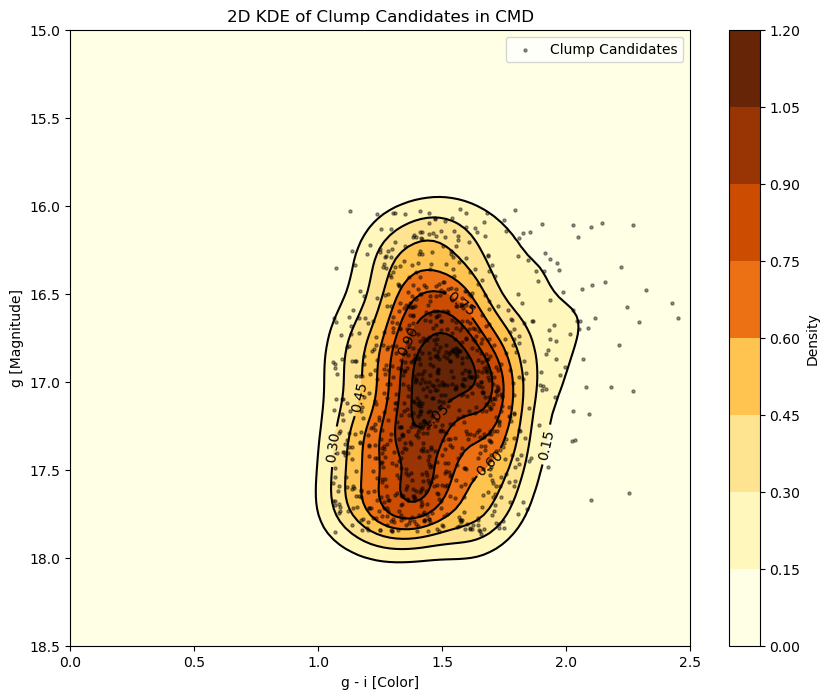

In [107]:
# --- 2D KDE for Red Clump Candidates ---
# Define x and y for the 2D KDE
x = clump_colors_g
y = clump_magnitudes_g

# Ensure that there is enough data for 2D KDE calculation (at least 2 points)
if len(x) < 2 or len(y) < 2:
    print("Not enough data points for 2D KDE after filtering. Skipping 2D KDE plot.")
else:
    # Define the plot limits based on your data and CMD parameters
    xmin, xmax = 0, 2.5
    ymin, ymax = 15, 18.5

    # Peform the kernel density estimate
    xx, yy = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
    positions = np.vstack([xx.ravel(), yy.ravel()])
    
    # Stack your x and y data for the KDE calculation
    # print(f"Shape of x: {x.shape}")
    # print(f"Shape of y: {y.shape}")
    values = np.vstack([x, y])
    
    # Create the KDE object
    kernel = st.gaussian_kde(values)
    
    # Evaluate the KDE on the grid
    f = np.reshape(kernel(positions).T, xx.shape)

    # Plotting the 2D KDE
    fig = plt.figure(figsize=(10, 8))
    ax = fig.gca()

    # Set plot limits
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    
    # Invert the y-axis
    ax.invert_yaxis()

    # Contourf plot (filled contours)
    cfset = ax.contourf(xx, yy, f, cmap=YlOrBr_cmap)
    
    # You can also add the data points themselves on top of the KDE plot
    ax.scatter(x, y, s=5, color='k', alpha=0.4, label='Clump Candidates')

    # Contour plot (lines only)
    cset = ax.contour(xx, yy, f, colors='k')
    
    # Label contours
    ax.clabel(cset, inline=1, fontsize=10)
    
    # Set labels and title
    ax.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
    ax.set_ylabel(f"{magnitude_band} [Magnitude]")
    ax.set_title('2D KDE of Clump Candidates in CMD')

    plt.colorbar(cfset, label='Density') # Add a color bar
    plt.legend()
    #plt.savefig('figures/gi_clump_2dkde.png')
    plt.show()

In [109]:
# Printing the results of the magnitude fit
print(
    f"{magnitude_band}_rc = {par_0g[2]} ± {np.sqrt(cov_0g[2, 2])}, "
    f"sigma_rc = {par_0g[4]} ± {np.sqrt(cov_0g[4, 4])}, "
    f"A_{magnitude_band} = {par_0g[2] - clumpmag0_g} ± {np.sqrt(cov_0g[2, 2])}"
     )
# Printing the results of the color fit
magnitude_rc = par_0g[2]
A_g = magnitude_rc - clumpmag0_g
color_rc = np.nanmedian(clump_candidates_g['mis_g'] - clump_candidates_g['mis_i'])
color_rc = par_1g[1]
E_color = color_rc - (red_clump["clump-" + color_band_1] - red_clump["clump-" + color_band_2]) # include error
E_color_err = np.sqrt(cov_1g[1,1])
tot2sel = A_g / E_color
print(f"E({color_band_1}-{color_band_2}) = {E_color} ± {E_color_err} , " 
      f"Tot/Sel = {tot2sel}"
     )

g_rc = 16.93923510944805 ± 0.029074879264899066, sigma_rc = 0.4620499625879435 ± 0.03697755633686887, A_g = 1.1017214590425244 ± 0.029074879264899066
E(g-i) = 0.45895885092246425 ± 0.01001386970749343 , Tot/Sel = 2.4004798182411506


In [111]:
# Printing the results of the magnitude fit
print(
    f"{color_band_2}_rc = {par_0i[2]} ± {np.sqrt(cov_0i[2, 2])}, "
    f"sigma_rc = {par_0i[4]} ± {np.sqrt(cov_0i[4, 4])}, "
    f"A_{color_band_2} = {par_0i[2] - clumpmag0_i} ± {np.sqrt(cov_0i[2, 2])}"
     )
# Printing the results of the color fit
magnitude_rc = par_0i[2]
A_i = magnitude_rc - clumpmag0_i
color_rc = np.nanmedian(clump_candidates_i['mis_g'] - clump_candidates_i['mis_i'])
color_rc = par_1i[1]
E_color = color_rc - (red_clump["clump-" + color_band_1] - red_clump["clump-" + color_band_2]) # include error
E_color_err = np.sqrt(cov_1i[1,1])
tot2sel = A_i / E_color
print(f"E({color_band_1}-{color_band_2}) = {E_color} ± {E_color_err} , " 
      f"Tot/Sel = {tot2sel}"
     )
print(magnitude_rc, clumpmag0_i)

i_rc = 15.418983409998445 ± 0.043229120382396284, sigma_rc = 0.539677305554194 ± 0.052903327766597036, A_i = 0.5755618176216704 ± 0.043229120382396284
E(g-i) = 0.4877461647510566 ± 0.008538156372085194 , Tot/Sel = 1.1800437588585335
15.418983409998445 14.843421592376774
